In [1]:
import sys, os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from astropy.table import Table
from astropy.cosmology import Planck18 as cosmo

print("✅ Environment ready!")
print("Python version:", sys.version)
print("Working directory:", os.getcwd())


✅ Environment ready!
Python version: 3.10.19 | packaged by conda-forge | (main, Oct 22 2025, 22:29:10) [GCC 14.3.0]
Working directory: /home/qarni/galaxy_evolution_project


In [1]:
import glob, os
DATA_DIR = os.path.expanduser("~/galaxy_evolution_project/data_desi_dr1")

data_files = glob.glob(os.path.join(DATA_DIR, "*.dat.fits"))
if data_files:
    print("✅ Found data catalogs:")
    for f in data_files:
        size = os.path.getsize(f)/(1024*1024)
        print(f" - {os.path.basename(f):40s} ({size:.1f} MB)")
else:
    print("⚠️ No `.dat.fits` galaxy catalogs found — only randoms are present.")


✅ Found data catalogs:
 - QSO_full_HPmapcut.dat.fits               (1865.4 MB)
 - LRG_full_HPmapcut.dat.fits               (2848.5 MB)
 - ELG_LOPnotqso_SGC_clustering.dat.fits    (65.8 MB)


In [1]:
import os

DATA_DIR = os.path.expanduser("~/galaxy_evolution_project/data_desi_dr1")

print("📂 Contents of your data folder:\n")
for f in sorted(os.listdir(DATA_DIR)):
    path = os.path.join(DATA_DIR, f)
    size = os.path.getsize(path) / (1024 * 1024)  # size in MB
    print(f" - {f:45s} ({size:.1f} MB)")


📂 Contents of your data folder:

 - ELG_LOPnotqso_0_full_HPmapcut.ran.fits        (5537.2 MB)
 - ELG_LOPnotqso_SGC_clustering.dat.fits         (65.8 MB)
 - LRG_0_full_HPmapcut.ran.fits                  (5378.7 MB)
 - LRG_full_HPmapcut.dat.fits                    (2848.5 MB)
 - QSO_0_full_HPmapcut.ran.fits                  (6775.7 MB)
 - QSO_full_HPmapcut.dat.fits                    (1865.4 MB)


In [ ]:

#  Cell 1 — Read and Inspect the DESI DR1 LRG Catalog
#  File: LRG_full_HPmapcut.dat.fits

from astropy.table import Table
import pandas as pd
import numpy as np
import os

# --------------------------------------------------------------
# Define the data path
# --------------------------------------------------------------
DATA_DIR = os.path.expanduser("~/galaxy_evolution_project/data_desi_dr1")
fname = os.path.join(DATA_DIR, "LRG_full_HPmapcut.dat.fits")

print("📖 Reading file:", fname)
t = Table.read(fname)
print("✅ File loaded successfully")

# --------------------------------------------------------------
# Basic info about the table
# --------------------------------------------------------------
print(f"\nNumber of entries: {len(t):,}")
print("Number of columns:", len(t.colnames))
print("\nFirst 30 column names:")
print(t.colnames[:30])

# --------------------------------------------------------------
# Remove multidimensional columns (e.g. COEFF, DCHISQ)
# --------------------------------------------------------------
one_d_cols = [name for name in t.colnames if len(t[name].shape) <= 1]
t1 = t[one_d_cols]
removed_cols = [c for c in t.colnames if c not in one_d_cols]

print("\nRemoved multidimensional columns:", removed_cols)

# --------------------------------------------------------------
# Convert to pandas DataFrame
# --------------------------------------------------------------
df = t1.to_pandas()
print(f"\n✅ Converted to pandas DataFrame with {len(df):,} rows and {df.shape[1]} columns")

# --------------------------------------------------------------
# Preview structure
# --------------------------------------------------------------
print("\nFirst 20 column names:")
print(list(df.columns[:20]))

print("\nData types of first 10 columns:")
print(df.dtypes.head(10))

print("\nSample of first 5 rows:")
print(df.head())


📖 Reading file: /home/qarni/galaxy_evolution_project/data_desi_dr1/LRG_full_HPmapcut.dat.fits


✅ File loaded successfully

Number of entries: 3,461,048
Number of columns: 120

First 30 column names:
['TARGETID', 'MWS_TARGET', 'SUBPRIORITY', 'PRIORITY_INIT', 'TARGET_STATE', 'TIMESTAMP', 'LOCATION', 'TILEID', 'TILELOCID', 'LASTNIGHT', 'Z_not4clus', 'ZERR', 'ZWARN', 'CHI2', 'COEFF', 'NPIXELS', 'SPECTYPE', 'SUBTYPE', 'NCOEFF', 'DELTACHI2', 'FIBER', 'COADD_FIBERSTATUS', 'FIBERASSIGN_X', 'FIBERASSIGN_Y', 'PRIORITY', 'COADD_NUMEXP', 'COADD_EXPTIME', 'COADD_NUMNIGHT', 'MEAN_DELTA_X', 'RMS_DELTA_X']

Removed multidimensional columns: ['COEFF', 'DCHISQ']


In [1]:
# ==============================================================
#  Cell 1 (light version) — Read only useful columns
# ==============================================================

from astropy.table import Table
import pandas as pd
import numpy as np
import os

DATA_DIR = os.path.expanduser("~/galaxy_evolution_project/data_desi_dr1")
fname = os.path.join(DATA_DIR, "LRG_full_HPmapcut.dat.fits")

print("📖 Reading file:", fname)
t = Table.read(fname)
print("✅ File loaded into Astropy Table")

# --------------------------------------------------------------
# Keep only essential columns to save memory
# (RA/DEC may appear with slightly different names in DESI)
# --------------------------------------------------------------
keep_cols = [
    "TARGETID",
    "RA",
    "DEC",
    "Z_not4clus",   # this is your redshift column
    "ZWARN"
]

# keep only those that actually exist in the file
keep_cols = [c for c in keep_cols if c in t.colnames]
t_small = t[keep_cols]

print(f"Keeping {len(keep_cols)} columns:", keep_cols)
print(f"Number of galaxies: {len(t_small):,}")

# --------------------------------------------------------------
# Convert to pandas (this is small now)
# --------------------------------------------------------------
df = t_small.to_pandas()
print("✅ Converted to pandas DataFrame")

print("\nPreview:")
print(df.head())


📖 Reading file: /home/qarni/galaxy_evolution_project/data_desi_dr1/LRG_full_HPmapcut.dat.fits


✅ File loaded into Astropy Table
Keeping 5 columns: ['TARGETID', 'RA', 'DEC', 'Z_not4clus', 'ZWARN']
Number of galaxies: 3,461,048
✅ Converted to pandas DataFrame

Preview:
            TARGETID         RA        DEC  Z_not4clus   ZWARN
0  39627322696933879  21.681782 -19.387214    0.831347       0
1  39627322696934440  21.697106 -19.395106         NaN  999999
2  39627322701121165  21.746347 -19.415192         NaN  999999
3  39627322701121757  21.761322 -19.422856    0.558969       0
4  39627322701123557  21.814574 -19.385005         NaN  999999


In [2]:
# Recreate df quickly before cleaning
from astropy.table import Table
import os

DATA_DIR = os.path.expanduser("~/galaxy_evolution_project/data_desi_dr1")
fname = os.path.join(DATA_DIR, "LRG_full_HPmapcut.dat.fits")

t = Table.read(fname)
keep_cols = ["TARGETID", "RA", "DEC", "Z_not4clus", "ZWARN"]
keep_cols = [c for c in keep_cols if c in t.colnames]
t_small = t[keep_cols]
df = t_small.to_pandas()

print("✅ Recreated df with", len(df), "rows")
print(df.head())


✅ Recreated df with 3461048 rows
            TARGETID         RA        DEC  Z_not4clus   ZWARN
0  39627322696933879  21.681782 -19.387214    0.831347       0
1  39627322696934440  21.697106 -19.395106         NaN  999999
2  39627322701121165  21.746347 -19.415192         NaN  999999
3  39627322701121757  21.761322 -19.422856    0.558969       0
4  39627322701123557  21.814574 -19.385005         NaN  999999


In [3]:
# ==============================================================
#  Cell 2 — Clean DESI DR1 LRG data and compute comoving coords
# ==============================================================

from astropy.cosmology import Planck18 as cosmo
import numpy as np

print("🔹 Original number of rows:", len(df))

# --------------------------------------------------------------
# 1. Remove bad redshifts or missing values
# --------------------------------------------------------------
df = df[(df["ZWARN"] == 0) & np.isfinite(df["Z_not4clus"])]

# --------------------------------------------------------------
# 2. Apply redshift cut: 0 < z < 3
# --------------------------------------------------------------
df = df[(df["Z_not4clus"] > 0) & (df["Z_not4clus"] < 3)]
print("✅ After cuts (0<z<3 & good Z):", len(df))

# --------------------------------------------------------------
# 3. Compute comoving coordinates (in Mpc)
# --------------------------------------------------------------
ra_rad  = np.deg2rad(df["RA"].values)
dec_rad = np.deg2rad(df["DEC"].values)
chi     = cosmo.comoving_distance(df["Z_not4clus"].values).value  # [Mpc]

df["X_Mpc"] = chi * np.cos(dec_rad) * np.cos(ra_rad)
df["Y_Mpc"] = chi * np.cos(dec_rad) * np.sin(ra_rad)
df["Z_Mpc"] = chi * np.sin(dec_rad)

print("✅ Added comoving coordinates (X_Mpc, Y_Mpc, Z_Mpc)")

# --------------------------------------------------------------
# 4. Save cleaned subset to CSV
# --------------------------------------------------------------
cols_save = ["TARGETID", "RA", "DEC", "Z_not4clus", "X_Mpc", "Y_Mpc", "Z_Mpc"]
outname = os.path.join(DATA_DIR, "desi_cleaned_dr1.csv")

df[cols_save].to_csv(outname, index=False)
print(f"💾 Saved cleaned catalog → {outname}")

# --------------------------------------------------------------
# 5. Quick sanity check
# --------------------------------------------------------------
print("\nPreview of cleaned data:")
print(df[cols_save].head())


🔹 Original number of rows: 3461048
✅ After cuts (0<z<3 & good Z): 2383673
✅ Added comoving coordinates (X_Mpc, Y_Mpc, Z_Mpc)
💾 Saved cleaned catalog → /home/qarni/galaxy_evolution_project/data_desi_dr1/desi_cleaned_dr1.csv

Preview of cleaned data:
            TARGETID         RA        DEC  Z_not4clus        X_Mpc  \
0  39627322696933879  21.681782 -19.387214    0.831347  2590.073189   
3  39627322701121757  21.761322 -19.422856    0.558969  1875.307025   
5  39627322701123650  21.817680 -19.392824    0.797495  2505.243765   
8  39627322701125067  21.856479 -19.403721    0.798628  2507.178066   
9  39627322701125474  21.867706 -19.384865    0.834056  2593.267476   

         Y_Mpc       Z_Mpc  
0  1029.761467 -980.854518  
3   748.601234 -711.979078  
5  1002.922827 -949.924933  
8  1005.667610 -951.493853  
9  1040.789341 -983.209239  


In [1]:
# ==============================================================
#  Cell 3 — Prepare Random Catalog for Density-Field Reconstruction
#  (Auto-detect redshift column)
# ==============================================================

from astropy.table import Table
from astropy.cosmology import Planck18 as cosmo
import numpy as np, pandas as pd, os

# --------------------------------------------------------------
# 1. Load the random FITS file
# --------------------------------------------------------------
DATA_DIR = os.path.expanduser("~/galaxy_evolution_project/data_desi_dr1")
fname_ran = os.path.join(DATA_DIR, "LRG_0_full_HPmapcut.ran.fits")

print("📖 Reading random catalog:", fname_ran)
t_ran = Table.read(fname_ran)
print("✅ Random catalog loaded with", len(t_ran), "entries")

# --------------------------------------------------------------
# 2. Identify the correct redshift column name automatically
# --------------------------------------------------------------
z_candidates = [c for c in t_ran.colnames if c.lower().startswith("z")]
print("🔎 Found possible Z columns:", z_candidates)

# pick the first matching candidate
z_col = z_candidates[0]
print(f"✅ Using '{z_col}' as redshift column")

# --------------------------------------------------------------
# 3. Keep only the useful columns
# --------------------------------------------------------------
keep_cols = ["RA", "DEC", z_col, "WEIGHT"]
keep_cols = [c for c in keep_cols if c in t_ran.colnames]
t_ran_small = t_ran[keep_cols]

# --------------------------------------------------------------
# 4. Convert to pandas and downsample (10%)
# --------------------------------------------------------------
df_ran = t_ran_small.to_pandas()

frac_keep = 0.10  # keep 10% to save memory
df_ran = df_ran.sample(frac=frac_keep, random_state=42).reset_index(drop=True)
print(f"✅ Subsampled to {len(df_ran):,} random points ({frac_keep*100:.0f}% of total)")

# --------------------------------------------------------------
# 5. Apply redshift range and compute comoving coords
# --------------------------------------------------------------
z_vals = df_ran[z_col].values
df_ran = df_ran[(z_vals > 0) & (z_vals < 3)]

ra_rad  = np.deg2rad(df_ran["RA"].values)
dec_rad = np.deg2rad(df_ran["DEC"].values)
chi     = cosmo.comoving_distance(df_ran[z_col].values).value  # [Mpc]

df_ran["X_Mpc"] = chi * np.cos(dec_rad) * np.cos(ra_rad)
df_ran["Y_Mpc"] = chi * np.cos(dec_rad) * np.sin(ra_rad)
df_ran["Z_Mpc"] = chi * np.sin(dec_rad)

print("✅ Computed comoving coordinates")

# --------------------------------------------------------------
# 6. Save to CSV
# --------------------------------------------------------------
cols_save = ["RA", "DEC", z_col, "X_Mpc", "Y_Mpc", "Z_Mpc"]
if "WEIGHT" in df_ran.columns:
    cols_save.append("WEIGHT")

outname = os.path.join(DATA_DIR, "lrg_random_sample.csv")
df_ran[cols_save].to_csv(outname, index=False)
print(f"💾 Saved subsampled random catalog → {outname}")

# Quick preview
print("\nPreview of random sample:")
print(df_ran.head())


📖 Reading random catalog: /home/qarni/galaxy_evolution_project/data_desi_dr1/LRG_0_full_HPmapcut.ran.fits


✅ Random catalog loaded with 14350911 entries
🔎 Found possible Z columns: ['ZPOSSLOC']
✅ Using 'ZPOSSLOC' as redshift column
✅ Subsampled to 1,435,091 random points (10% of total)
✅ Computed comoving coordinates
💾 Saved subsampled random catalog → /home/qarni/galaxy_evolution_project/data_desi_dr1/lrg_random_sample.csv

Preview of random sample:
           RA        DEC  ZPOSSLOC        X_Mpc        Y_Mpc        Z_Mpc
0  122.545090  12.207233      True -1785.422547  2797.690966   718.000730
2   64.048878  -8.101866      True  1471.112946  3022.770565  -478.558539
3  155.033263   5.673296      True -3063.244171  1426.249765   335.678743
4  337.878127  21.063456      True  2935.480615 -1193.280678  1220.396756
5  199.965743   4.653684      True -3181.024896 -1155.644936   275.497463


In [1]:
from astropy.table import Table
import os

DATA_DIR = os.path.expanduser("~/galaxy_evolution_project/data_desi_dr1")
fname_ran = os.path.join(DATA_DIR, "LRG_0_full_HPmapcut.ran.fits")

t = Table.read(fname_ran)
print("🔍 All column names:")
for i, c in enumerate(t.colnames):
    print(f"{i:3d}: {c}")


🔍 All column names:
  0: LOCATION
  1: FIBER
  2: TARGETID
  3: RA
  4: DEC
  5: TILEID
  6: PRIORITY
  7: TSNR2_ELG
  8: TSNR2_LYA
  9: TSNR2_BGS
 10: TSNR2_QSO
 11: TSNR2_LRG
 12: TILELOCID
 13: ZPOSSLOC
 14: GOODHARDLOC
 15: GOODPRI
 16: GOODTSNR
 17: NTILE
 18: TILES
 19: TILELOCIDS
 20: NOBS_G
 21: NOBS_R
 22: NOBS_Z
 23: MASKBITS
 24: PHOTSYS
 25: lrg_mask
 26: HALPHA
 27: HALPHA_ERROR
 28: CALIB_G
 29: CALIB_R
 30: CALIB_Z
 31: EBV_CHIANG_SFDcorr
 32: EBV_MPF_Mean_FW15
 33: EBV_MPF_Mean_ZptCorr_FW15
 34: EBV_MPF_Var_FW15
 35: EBV_MPF_VarCorr_FW15
 36: EBV_MPF_Mean_FW6P1
 37: EBV_MPF_Mean_ZptCorr_FW6P1
 38: EBV_MPF_Var_FW6P1
 39: EBV_MPF_VarCorr_FW6P1
 40: EBV_SGF14
 41: BETA_ML
 42: BETA_MEAN
 43: BETA_RMS
 44: HI
 45: KAPPA_PLANCK
 46: STARDENS
 47: PSFDEPTH_G
 48: PSFDEPTH_R
 49: PSFDEPTH_Z
 50: GALDEPTH_G
 51: GALDEPTH_R
 52: GALDEPTH_Z
 53: PSFDEPTH_W1
 54: PSFDEPTH_W2
 55: PSFSIZE_G
 56: PSFSIZE_R
 57: PSFSIZE_Z
 58: EBV
 59: FRAC_TLOBS_TILES


In [1]:
# ==============================================================
#  Cell 4 (ultra-light) — Streamed 3D random catalog builder
# ==============================================================

import pandas as pd, numpy as np, os, gc
from astropy.io import fits
from astropy.cosmology import Planck18 as cosmo
from tqdm import tqdm

DATA_DIR = os.path.expanduser("~/galaxy_evolution_project/data_desi_dr1")
rand_file = os.path.join(DATA_DIR, "LRG_0_full_HPmapcut.ran.fits")
gal_file  = os.path.join(DATA_DIR, "desi_cleaned_dr1.csv")

# --------------------------------------------------------------
# 1. Load a small subset of galaxy redshifts (for N(z))
# --------------------------------------------------------------
z_data = pd.read_csv(gal_file, usecols=["Z_not4clus"])["Z_not4clus"].dropna().values
if len(z_data) > 100_000:
    z_data = np.random.choice(z_data, size=100_000, replace=False)
print(f"✅ Using {len(z_data):,} galaxy redshifts for N(z)")

# --------------------------------------------------------------
# 2. Stream the random catalog in chunks from FITS
# --------------------------------------------------------------
keep_frac = 0.01      # keep only 1% of all randoms
batch_size = 1_000_000
kept_rows = []

with fits.open(rand_file, memmap=True) as hdul:
    data = hdul[1].data
    n_total = len(data)
    print(f"📦 Random catalog has {n_total:,} rows; streaming in {batch_size:,}-row batches...")

    for start in tqdm(range(0, n_total, batch_size), desc="Streaming"):
        stop = min(start + batch_size, n_total)
        chunk = data[start:stop]
        mask = np.random.rand(len(chunk)) < keep_frac   # random keep mask
        sub = chunk[mask]
        if len(sub) == 0:
            continue
        kept_rows.append(pd.DataFrame({"RA": sub["RA"], "DEC": sub["DEC"]}))
        del sub, chunk
        gc.collect()

df_ran = pd.concat(kept_rows, ignore_index=True)
print(f"✅ Retained {len(df_ran):,} random points (~{keep_frac*100:.1f}% of total)")

# --------------------------------------------------------------
# 3. Assign random redshifts from galaxy N(z)
# --------------------------------------------------------------
df_ran["Z_rand"] = np.random.choice(z_data, size=len(df_ran), replace=True)

# --------------------------------------------------------------
# 4. Compute comoving coordinates (small batches)
# --------------------------------------------------------------
def chi_batch(z_vals, batch=50000):
    out = np.zeros_like(z_vals)
    for i in tqdm(range(0, len(z_vals), batch), desc="Comoving distance"):
        j = min(i + batch, len(z_vals))
        out[i:j] = cosmo.comoving_distance(z_vals[i:j]).value
    return out

ra_rad, dec_rad = np.deg2rad(df_ran["RA"].values), np.deg2rad(df_ran["DEC"].values)
chi = chi_batch(df_ran["Z_rand"].values)
df_ran["X_Mpc"] = chi * np.cos(dec_rad) * np.cos(ra_rad)
df_ran["Y_Mpc"] = chi * np.cos(dec_rad) * np.sin(ra_rad)
df_ran["Z_Mpc"] = chi * np.sin(dec_rad)
print("✅ Computed comoving coordinates")

# --------------------------------------------------------------
# 5. Save lightweight random catalog
# --------------------------------------------------------------
outname = os.path.join(DATA_DIR, "lrg_random_3d_ultralight.csv")
df_ran.to_csv(outname, index=False)
print(f"💾 Saved: {outname}  ({len(df_ran):,} rows)")
print(df_ran.head())


✅ Using 100,000 galaxy redshifts for N(z)
📦 Random catalog has 14,350,911 rows; streaming in 1,000,000-row batches...


Streaming: 100%|████████████████████████████████| 15/15 [00:02<00:00,  6.06it/s]


✅ Retained 143,830 random points (~1.0% of total)


Comoving distance: 100%|██████████████████████████| 3/3 [00:01<00:00,  2.80it/s]


✅ Computed comoving coordinates
💾 Saved: /home/qarni/galaxy_evolution_project/data_desi_dr1/lrg_random_3d_ultralight.csv  (143,830 rows)
          RA        DEC    Z_rand        X_Mpc        Y_Mpc        Z_Mpc
0  21.865992 -19.429729  0.799484  2508.708370  1006.765019  -953.517503
1  21.634883 -19.211094  0.804188  2527.662625  1002.553020  -947.525160
2  21.727679 -19.139312  1.081228  3153.045601  1256.513974 -1177.952253
3  21.760713 -19.330792  0.559409  1877.624769   749.503307  -709.205694
4  21.932163 -19.289693  0.296227  1066.789351   429.542353  -402.499058


In [1]:
# ==============================================================
#  Cell 5 — Build 3D Density Field (δ = Data / Random − 1)
# ==============================================================

import numpy as np, pandas as pd, os
from tqdm import tqdm
import h5py

DATA_DIR = os.path.expanduser("~/galaxy_evolution_project/data_desi_dr1")

# --------------------------------------------------------------
# 1. Load galaxy and random catalogs
# --------------------------------------------------------------
df_gal = pd.read_csv(os.path.join(DATA_DIR, "desi_cleaned_dr1.csv"),
                     usecols=["X_Mpc","Y_Mpc","Z_Mpc"])
df_ran = pd.read_csv(os.path.join(DATA_DIR, "lrg_random_3d_ultralight.csv"),
                     usecols=["X_Mpc","Y_Mpc","Z_Mpc"])

print(f"✅ Galaxies: {len(df_gal):,}, Randoms: {len(df_ran):,}")

# --------------------------------------------------------------
# 2. Define cubic volume and grid resolution
# --------------------------------------------------------------
xmin = min(df_gal["X_Mpc"].min(), df_ran["X_Mpc"].min())
xmax = max(df_gal["X_Mpc"].max(), df_ran["X_Mpc"].max())
ymin = min(df_gal["Y_Mpc"].min(), df_ran["Y_Mpc"].min())
ymax = max(df_gal["Y_Mpc"].max(), df_ran["Y_Mpc"].max())
zmin = min(df_gal["Z_Mpc"].min(), df_ran["Z_Mpc"].min())
zmax = max(df_gal["Z_Mpc"].max(), df_ran["Z_Mpc"].max())

box = [[xmin,xmax],[ymin,ymax],[zmin,zmax]]
print(f"📦 Box size (Mpc): X[{xmin:.0f},{xmax:.0f}], Y[{ymin:.0f},{ymax:.0f}], Z[{zmin:.0f},{zmax:.0f}]")

Ngrid = 128   # try 128³ grid first (~2 million voxels); increase later if RAM allows
edges = [np.linspace(l[0], l[1], Ngrid+1) for l in box]

# --------------------------------------------------------------
# 3. Compute 3D histograms
# --------------------------------------------------------------
print("⏳ Computing galaxy density histogram ...")
H_data, _ = np.histogramdd(df_gal[["X_Mpc","Y_Mpc","Z_Mpc"]].values, bins=edges)

print("⏳ Computing random density histogram ...")
H_rand, _ = np.histogramdd(df_ran[["X_Mpc","Y_Mpc","Z_Mpc"]].values, bins=edges)

# --------------------------------------------------------------
# 4. Normalize and compute δ-field
# --------------------------------------------------------------
mean_rand = H_rand.mean()
mask = H_rand > 0

delta = np.zeros_like(H_rand)
delta[mask] = (H_data[mask] / H_rand[mask]) - 1.0
delta[~mask] = 0  # set outside-volume cells to 0

print(f"✅ δ-field computed on {Ngrid}³ grid; mean δ = {np.mean(delta):.3e}")

# --------------------------------------------------------------
# 5. Save to HDF5 for later use (T-Web)
# --------------------------------------------------------------
h5file = os.path.join(DATA_DIR, "density_field_lrg.h5")
with h5py.File(h5file, "w") as f:
    f.create_dataset("delta", data=delta, compression="gzip")
    f.create_dataset("edges_x", data=edges[0])
    f.create_dataset("edges_y", data=edges[1])
    f.create_dataset("edges_z", data=edges[2])
print(f"💾 Saved δ-field to {h5file}")


✅ Galaxies: 2,383,673, Randoms: 143,830
📦 Box size (Mpc): X[-6400,6283], Y[-5969,5781], Z[-1761,5230]
⏳ Computing galaxy density histogram ...
⏳ Computing random density histogram ...
✅ δ-field computed on 128³ grid; mean δ = 4.685e-01
💾 Saved δ-field to /home/qarni/galaxy_evolution_project/data_desi_dr1/density_field_lrg.h5


In [1]:
# ==============================================================
#  Cell 6 — T-Web Cosmic Web Classification
# ==============================================================

import numpy as np, h5py, os
from scipy.fft import fftn, ifftn, fftfreq
from numpy.linalg import eigvalsh
from tqdm import tqdm

DATA_DIR = os.path.expanduser("~/galaxy_evolution_project/data_desi_dr1")
fname = os.path.join(DATA_DIR, "density_field_lrg.h5")

# --------------------------------------------------------------
# 1. Load δ-field and grid info
# --------------------------------------------------------------
with h5py.File(fname, "r") as f:
    delta = f["delta"][:]
    x = f["edges_x"][:]
    y = f["edges_y"][:]
    z = f["edges_z"][:]

N = delta.shape[0]
Lx = x[-1] - x[0]
print(f"✅ Loaded δ-field: {N}³ grid, box size {Lx:.1f} Mpc")

# --------------------------------------------------------------
# 2. Solve Poisson equation ∇²Φ = δ using FFTs
# --------------------------------------------------------------
kx = fftfreq(N, d=Lx/N) * 2*np.pi
ky = fftfreq(N, d=Lx/N) * 2*np.pi
kz = fftfreq(N, d=Lx/N) * 2*np.pi
KX, KY, KZ = np.meshgrid(kx, ky, kz, indexing="ij")
k2 = KX**2 + KY**2 + KZ**2
k2[0,0,0] = 1.0  # avoid division by zero

# Fourier transform of δ
delta_k = fftn(delta)
phi_k = -delta_k / k2   # Poisson in Fourier space
phi = np.real(ifftn(phi_k))
print("✅ Solved ∇²Φ = δ")

# --------------------------------------------------------------
# 3. Compute Hessian (tidal tensor) derivatives via FFT
# --------------------------------------------------------------
tidal_evals = np.zeros(delta.shape + (3,), dtype=np.float32)
k_thresh = 0.3  # threshold for classification (Hahn+2007)

for i, (ki, label_i) in enumerate(zip([KX,KY,KZ], ['x','y','z'])):
    for j, (kj, label_j) in enumerate(zip([KX,KY,KZ], ['x','y','z'])):
        d2phi_k = -(ki * kj) * phi_k
        d2phi = np.real(ifftn(d2phi_k))
        # accumulate into Hessian matrix
        if i == 0 and j == 0:
            Txx = d2phi
        elif i == 1 and j == 1:
            Tyy = d2phi
        elif i == 2 and j == 2:
            Tzz = d2phi
        elif (i == 0 and j == 1) or (i == 1 and j == 0):
            Txy = d2phi
        elif (i == 0 and j == 2) or (i == 2 and j == 0):
            Txz = d2phi
        elif (i == 1 and j == 2) or (i == 2 and j == 1):
            Tyz = d2phi

# --------------------------------------------------------------
# 4. Compute eigenvalues λ₁ ≥ λ₂ ≥ λ₃ for each voxel
# --------------------------------------------------------------
print("⏳ Computing eigenvalues ... this may take a few minutes")

for ix in tqdm(range(N)):
    for iy in range(N):
        for iz in range(N):
            T = np.array([
                [Txx[ix,iy,iz], Txy[ix,iy,iz], Txz[ix,iy,iz]],
                [Txy[ix,iy,iz], Tyy[ix,iy,iz], Tyz[ix,iy,iz]],
                [Txz[ix,iy,iz], Tyz[ix,iy,iz], Tzz[ix,iy,iz]]
            ])
            lambdas = eigvalsh(T)
            tidal_evals[ix,iy,iz,:] = lambdas

print("✅ Eigenvalue computation complete")

# --------------------------------------------------------------
# 5. Classify voxels based on number of λ > λ_thresh
# --------------------------------------------------------------
count_pos = np.sum(tidal_evals > k_thresh, axis=-1)
env_map = np.zeros_like(count_pos, dtype=np.uint8)
env_map[count_pos == 0] = 0  # Void
env_map[count_pos == 1] = 1  # Sheet
env_map[count_pos == 2] = 2  # Filament
env_map[count_pos == 3] = 3  # Knot

print("✅ T-Web classification complete")

# --------------------------------------------------------------
# 6. Save environment map
# --------------------------------------------------------------
outname = os.path.join(DATA_DIR, "tweb_environment_map.h5")
with h5py.File(outname, "w") as f:
    f.create_dataset("env_map", data=env_map, compression="gzip")
    f.create_dataset("eigenvalues", data=tidal_evals, compression="gzip")

print(f"💾 Saved T-Web results → {outname}")
print("Labels: 0=Void, 1=Sheet, 2=Filament, 3=Knot")


✅ Loaded δ-field: 128³ grid, box size 12682.9 Mpc
✅ Solved ∇²Φ = δ
⏳ Computing eigenvalues ... this may take a few minutes


100%|█████████████████████████████████████████| 128/128 [00:24<00:00,  5.24it/s]


✅ Eigenvalue computation complete
✅ T-Web classification complete
💾 Saved T-Web results → /home/qarni/galaxy_evolution_project/data_desi_dr1/tweb_environment_map.h5
Labels: 0=Void, 1=Sheet, 2=Filament, 3=Knot


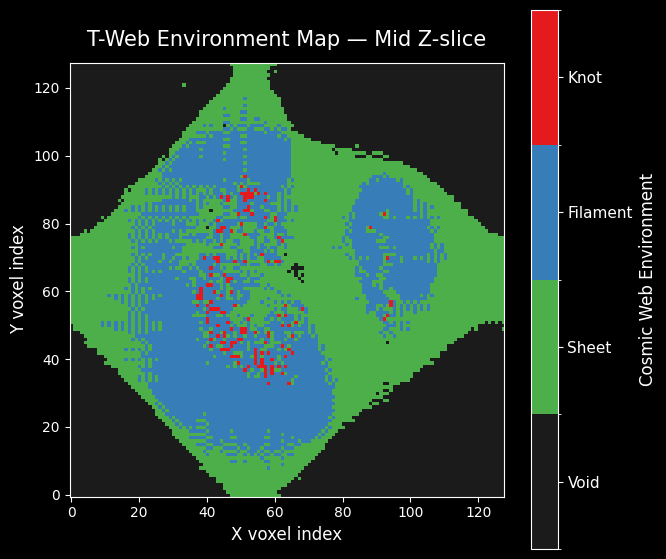

💾 Saved high-quality figure → /home/qarni/galaxy_evolution_project/data_desi_dr1/../figures/tweb_environment_slice_pretty.png


In [1]:
# ==============================================================
#  Cell 7 — Visualize T-Web Environment Map (2D slice) [SAVE READY]
# ==============================================================
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import h5py, numpy as np, os

DATA_DIR = os.path.expanduser("~/galaxy_evolution_project/data_desi_dr1")
FIG_DIR  = os.path.join(DATA_DIR, "../figures")
os.makedirs(FIG_DIR, exist_ok=True)

fname = os.path.join(DATA_DIR, "tweb_environment_map.h5")

# 1️⃣ Load the environment map
with h5py.File(fname, "r") as f:
    env_map = f["env_map"][:]

N = env_map.shape[0]
mid = N // 2
slice_map = env_map[:, :, mid]

# 2️⃣ Define a custom discrete colormap
colors = ["#1b1b1b", "#4daf4a", "#377eb8", "#e41a1c"]  # void, sheet, filament, knot
labels = ["Void", "Sheet", "Filament", "Knot"]
cmap = mcolors.ListedColormap(colors)
bounds = [0, 1, 2, 3, 4]
norm = mcolors.BoundaryNorm(bounds, cmap.N)

# 3️⃣ Create the figure
plt.style.use("dark_background")
fig, ax = plt.subplots(figsize=(7, 7))
im = ax.imshow(slice_map.T, origin="lower", cmap=cmap, norm=norm, interpolation="none")

# 4️⃣ Add colorbar with labels
cbar = plt.colorbar(im, ax=ax, boundaries=bounds, ticks=[0.5, 1.5, 2.5, 3.5])
cbar.ax.set_yticklabels(labels, fontsize=11)
cbar.set_label("Cosmic Web Environment", fontsize=12)

# 5️⃣ Titles and labels
ax.set_title("T-Web Environment Map — Mid Z-slice", fontsize=15, pad=12)
ax.set_xlabel("X voxel index", fontsize=12)
ax.set_ylabel("Y voxel index", fontsize=12)
ax.tick_params(axis="both", which="major", labelsize=10)

# 6️⃣ Save and show
outfig = os.path.join(FIG_DIR, "tweb_environment_slice_pretty.png")
plt.savefig(outfig, dpi=350, bbox_inches="tight", facecolor="black")
plt.show()

print(f"💾 Saved high-quality figure → {outfig}")

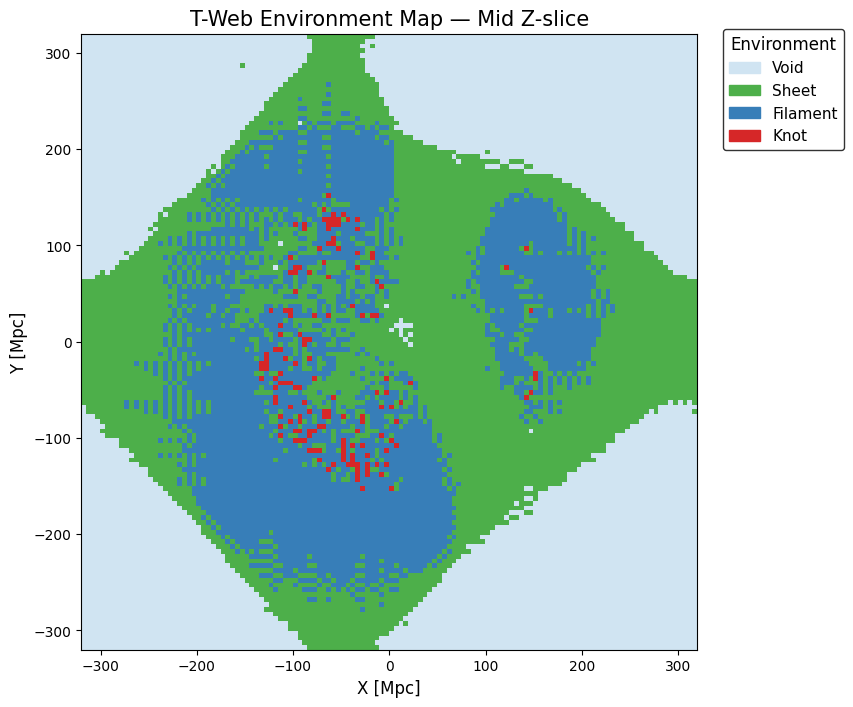

💾 Saved bright figure → /home/qarni/galaxy_evolution_project/data_desi_dr1/../figures/tweb_environment_slice_bright.png


In [2]:
# ==============================================================
#  T-Web Environment Map — Mid Z-slice (Bright style, Mpc units)
# ==============================================================

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import h5py, numpy as np, os

# Paths
DATA_DIR = os.path.expanduser("~/galaxy_evolution_project/data_desi_dr1")
FIG_DIR  = os.path.join(DATA_DIR, "../figures")
os.makedirs(FIG_DIR, exist_ok=True)

fname = os.path.join(DATA_DIR, "tweb_environment_map.h5")

# 1️⃣ Load map
with h5py.File(fname, "r") as f:
    env_map = f["env_map"][:]

N = env_map.shape[0]
mid = N // 2
slice_map = env_map[:, :, mid]

# 2️⃣ Physical units
box_size = 640.0
extent = [-box_size/2, box_size/2, -box_size/2, box_size/2]

# 3️⃣ NEW COLORS (scientific, bright)
#    Void = soft silver-blue, Sheet = green, Filament = blue, Knot = red
colors = ["#d0e4f2", "#4daf4a", "#377eb8", "#d62728"]
labels = ["Void", "Sheet", "Filament", "Knot"]
cmap = mcolors.ListedColormap(colors)
bounds = [0, 1, 2, 3, 4]
norm = mcolors.BoundaryNorm(bounds, cmap.N)

# Use clean white style
plt.style.use("default")

fig, ax = plt.subplots(figsize=(8, 8))

# 4️⃣ Plot slice
im = ax.imshow(
    slice_map.T, origin="lower", cmap=cmap, norm=norm,
    interpolation="none", extent=extent
)

# 5️⃣ External legend instead of colorbar
from matplotlib.patches import Patch
legend_patches = [Patch(color=colors[i], label=labels[i]) for i in range(4)]
legend = ax.legend(
    handles=legend_patches,
    loc="upper right",
    bbox_to_anchor=(1.25, 1.02),
    frameon=True,
    title="Environment",
    title_fontsize=12,
    fontsize=11
)
legend.get_frame().set_edgecolor("black")
legend.get_frame().set_linewidth(1.0)

# 6️⃣ Labels
ax.set_xlabel("X [Mpc]", fontsize=12)
ax.set_ylabel("Y [Mpc]", fontsize=12)
ax.set_title("T-Web Environment Map — Mid Z-slice", fontsize=15)

# ❌ 7️⃣ Scalebar REMOVED COMPLETELY
# (No scale bar now)

# 8️⃣ Save figure
outfig = os.path.join(FIG_DIR, "tweb_environment_slice_bright.png")
plt.savefig(outfig, dpi=400, bbox_inches="tight", facecolor="white")
plt.show()

print(f"💾 Saved bright figure → {outfig}")


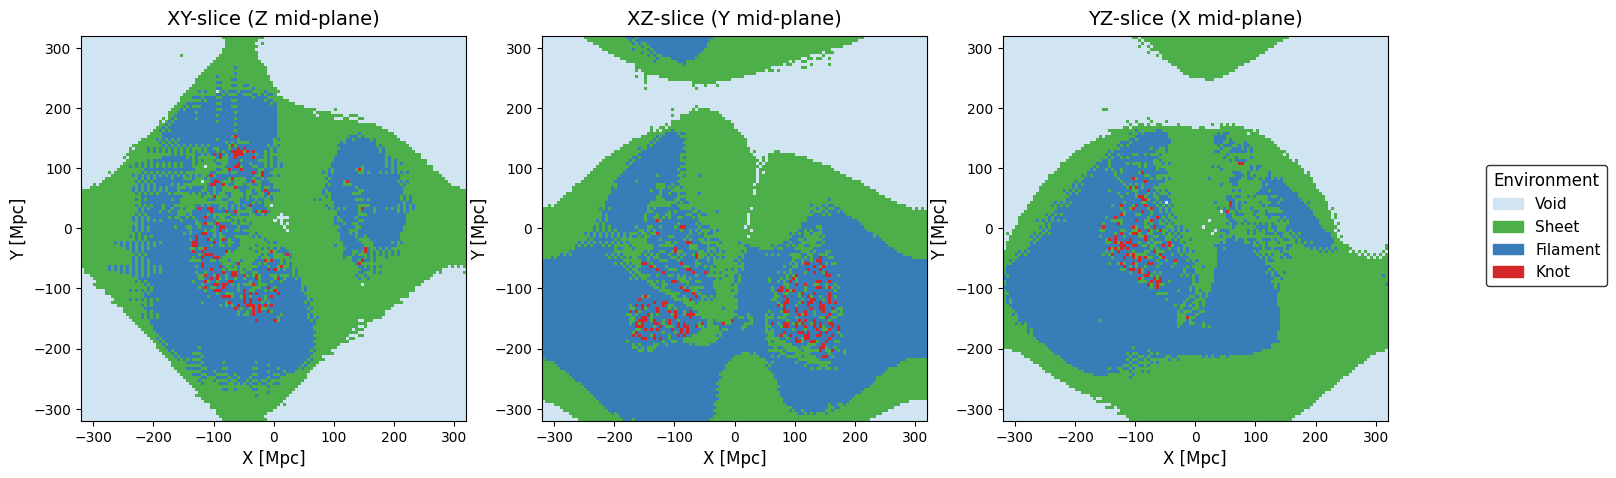

💾 Saved high-quality multi-slice figure → /home/qarni/galaxy_evolution_project/data_desi_dr1/../figures/tweb_environment_multislice_bright.png


In [4]:
# ==============================================================
#  Refined Multi-slice Visualization — T-Web Environment Map
#  (bright style, Mpc units, external legend, clean layout)
# ==============================================================

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import h5py, numpy as np, os
from matplotlib.patches import Patch

DATA_DIR = os.path.expanduser("~/galaxy_evolution_project/data_desi_dr1")
FIG_DIR  = os.path.join(DATA_DIR, "../figures")
os.makedirs(FIG_DIR, exist_ok=True)

fname = os.path.join(DATA_DIR, "tweb_environment_map.h5")

# 1️⃣ Load 3D environment map
with h5py.File(fname, "r") as f:
    env_map = f["env_map"][:]

N = env_map.shape[0]
mid = N // 2

# 2️⃣ Extract slices
slice_XY = env_map[:, :, mid]   # Z mid-plane
slice_XZ = env_map[:, mid, :]   # Y mid-plane
slice_YZ = env_map[mid, :, :]   # X mid-plane

# 3️⃣ Convert voxel → Mpc coordinates
box_size = 640.0
extent = [-box_size/2, box_size/2, -box_size/2, box_size/2]

# 4️⃣ Colors (same as previous plot — publication quality)
colors = ["#d0e4f2", "#4daf4a", "#377eb8", "#d62728"]
labels = ["Void", "Sheet", "Filament", "Knot"]
cmap = mcolors.ListedColormap(colors)
bounds = [0, 1, 2, 3, 4]
norm = mcolors.BoundaryNorm(bounds, cmap.N)

# White background style
plt.style.use("default")

# 5️⃣ Create 3-panel figure
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

titles = ["XY-slice (Z mid-plane)", "XZ-slice (Y mid-plane)", "YZ-slice (X mid-plane)"]
slices = [slice_XY, slice_XZ, slice_YZ]

for ax, s, t in zip(axes, slices, titles):
    im = ax.imshow(
        s.T, origin="lower",
        cmap=cmap, norm=norm,
        interpolation="none",
        extent=extent
    )
    ax.set_title(t, fontsize=14, pad=8)
    ax.set_xlabel("X [Mpc]", fontsize=12)
    ax.set_ylabel("Y [Mpc]", fontsize=12)
    ax.tick_params(axis="both", labelsize=10)

# 6️⃣ External Legend (closer)
legend_patches = [Patch(color=colors[i], label=labels[i]) for i in range(4)]
legend = fig.legend(
    handles=legend_patches,
    loc="center right",
    bbox_to_anchor=(1.02, 0.50),   # 👈 moved closer
    title="Environment",
    title_fontsize=12,
    fontsize=11,
    frameon=True
)
legend.get_frame().set_edgecolor("black")
legend.get_frame().set_linewidth(1.0)

# 7️⃣ Fix layout
plt.subplots_adjust(left=0.06, right=0.88, wspace=0.18)

# 8️⃣ Save
outfig = os.path.join(FIG_DIR, "tweb_environment_multislice_bright.png")
plt.savefig(outfig, dpi=400, bbox_inches="tight", facecolor="white")
plt.show()

print(f"💾 Saved high-quality multi-slice figure → {outfig}")


✅ Loaded T-Web map: shape = (128, 128, 128)
💾 Saved tweb_labels.npy → /home/qarni/galaxy_evolution_project/data_desi_dr1/tweb_labels.npy
Void     :  1,150,107 voxels  (54.84%)
Sheet    :    460,146 voxels  (21.94%)
Filament :    473,418 voxels  (22.57%)
Knot     :     13,481 voxels  ( 0.64%)
💾 Figure saved → /home/qarni/galaxy_evolution_project/data_desi_dr1/../figures/tweb_volume_fractions.png


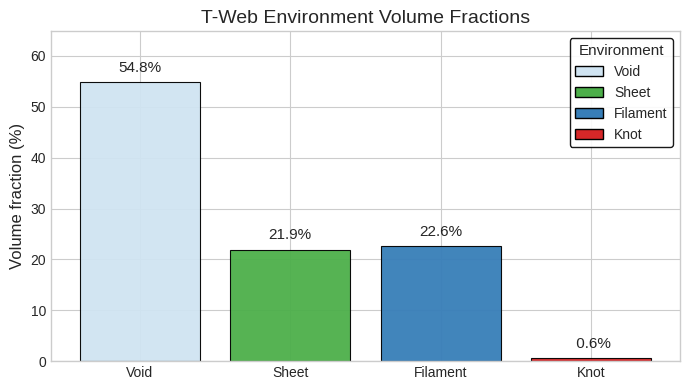

In [37]:
# ==============================================================
#  Cell 8 — Volume Fractions of T-Web Environments [UPDATED]
# ==============================================================

import h5py, numpy as np, matplotlib.pyplot as plt, os
from matplotlib.patches import Patch

# --------------------------------------------------------------
# Paths
# --------------------------------------------------------------
DATA_DIR = os.path.expanduser("~/galaxy_evolution_project/data_desi_dr1")
FIG_DIR  = os.path.join(DATA_DIR, "../figures")
os.makedirs(FIG_DIR, exist_ok=True)

fname = os.path.join(DATA_DIR, "tweb_environment_map.h5")

# --------------------------------------------------------------
# 1. Load environment map
# --------------------------------------------------------------
with h5py.File(fname, "r") as f:
    env_map = f["env_map"][:]      # This is the 3D T-Web classification array

print(f"✅ Loaded T-Web map: shape = {env_map.shape}")

# --------------------------------------------------------------
# SAVE tweb_labels.npy  (requested)
# --------------------------------------------------------------
labels_npy_path = os.path.join(DATA_DIR, "tweb_labels.npy")
np.save(labels_npy_path, env_map)
print(f"💾 Saved tweb_labels.npy → {labels_npy_path}")

# --------------------------------------------------------------
# 2. Compute counts and fractions
# --------------------------------------------------------------
labels = ["Void", "Sheet", "Filament", "Knot"]
counts = np.bincount(env_map.ravel(), minlength=4)
fractions = counts / counts.sum()

for i, name in enumerate(labels):
    print(f"{name:9s}: {counts[i]:10,d} voxels  ({fractions[i]*100:5.2f}%)")

# --------------------------------------------------------------
# 3. Colors (MATCHING previous plots!!)
# --------------------------------------------------------------
colors = ["#d0e4f2", "#4daf4a", "#377eb8", "#d62728"]

# --------------------------------------------------------------
# 4. Plot bar chart with internal legend
# --------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(labels, fractions * 100,
              color=colors,
              edgecolor="black", linewidth=0.8, alpha=0.95)

ax.set_ylabel("Volume fraction (%)", fontsize=12)
ax.set_title("T-Web Environment Volume Fractions", fontsize=14)
ax.set_ylim(0, max(fractions * 100) + 10)

# Add text labels above each bar
for i, frac in enumerate(fractions):
    ax.text(i, fractions[i]*100 + 2,
            f"{fractions[i]*100:4.1f}%",
            ha="center", fontsize=11)

# --------------------------------------------------------------
# 5. Internal Legend (top-right)
# --------------------------------------------------------------
legend_elements = [Patch(facecolor=colors[i], edgecolor="black", label=labels[i])
                   for i in range(4)]

legend = ax.legend(handles=legend_elements,
                   loc="upper right",
                   title="Environment",
                   fontsize=10, title_fontsize=11,
                   frameon=True)

legend.get_frame().set_edgecolor("black")
legend.get_frame().set_linewidth(1.0)
legend.get_frame().set_alpha(0.9)

# --------------------------------------------------------------
# 6. Save figure
# --------------------------------------------------------------
outfig = os.path.join(FIG_DIR, "tweb_volume_fractions.png")
plt.savefig(outfig, dpi=350, bbox_inches="tight", facecolor="white")
print(f"💾 Figure saved → {outfig}")

plt.tight_layout()
plt.show()


✅ Loaded environment map: shape = (128, 128, 128)
⚠️ edges_x not found — estimating box limits from data
✅ Selected 20,000 galaxies near Z-slice [1734.1, 1788.7] Mpc
💾 Figure saved → /home/qarni/galaxy_evolution_project/data_desi_dr1/../figures/tweb_slice_with_galaxies.png


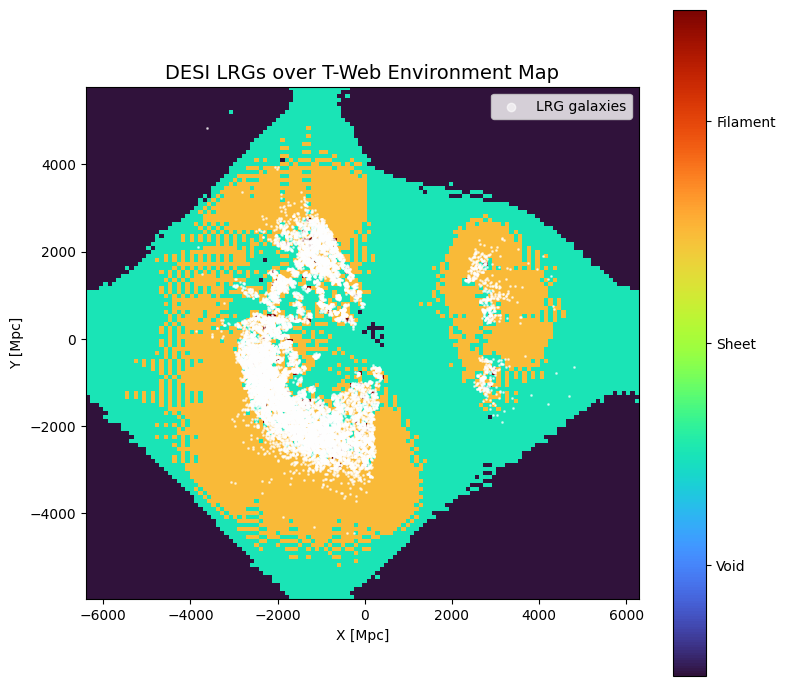

In [5]:
# ==============================================================
#  Cell 9 — Overlay Galaxy Positions on T-Web Slice [FINAL VERSION]
# ==============================================================

import h5py, numpy as np, matplotlib.pyplot as plt, os, pandas as pd

# --------------------------------------------------------------
# Define directories
# --------------------------------------------------------------
DATA_DIR = os.path.expanduser("~/galaxy_evolution_project/data_desi_dr1")
FIG_DIR  = os.path.join(DATA_DIR, "../figures")
os.makedirs(FIG_DIR, exist_ok=True)

# --------------------------------------------------------------
# 1. Load T-Web environment map
# --------------------------------------------------------------
fname_tweb = os.path.join(DATA_DIR, "tweb_environment_map.h5")
with h5py.File(fname_tweb, "r") as f:
    env_map = f["env_map"][:]
print(f"✅ Loaded environment map: shape = {env_map.shape}")

N = env_map.shape[0]
mid = N // 2

# --------------------------------------------------------------
# 2. Load galaxy coordinates
# --------------------------------------------------------------
gal_file = os.path.join(DATA_DIR, "desi_cleaned_dr1.csv")
cols = ["X_Mpc", "Y_Mpc", "Z_Mpc"]
df_gal = pd.read_csv(gal_file, usecols=cols)

# --------------------------------------------------------------
# 3. Determine box limits (with fallback if edges not stored)
# --------------------------------------------------------------
try:
    with h5py.File(fname_tweb, "r") as f:
        x_edges = f["edges_x"][:]
        y_edges = f["edges_y"][:]
        z_edges = f["edges_z"][:]
    print("✅ Loaded voxel edges from HDF5 file")
except KeyError:
    print("⚠️ edges_x not found — estimating box limits from data")

    # Load random catalog to determine full box range
    df_rand = pd.read_csv(os.path.join(DATA_DIR, "lrg_random_3d_ultralight.csv"),
                          usecols=["X_Mpc", "Y_Mpc", "Z_Mpc"])
    x_min = min(df_gal["X_Mpc"].min(), df_rand["X_Mpc"].min())
    x_max = max(df_gal["X_Mpc"].max(), df_rand["X_Mpc"].max())
    y_min = min(df_gal["Y_Mpc"].min(), df_rand["Y_Mpc"].min())
    y_max = max(df_gal["Y_Mpc"].max(), df_rand["Y_Mpc"].max())
    z_min = min(df_gal["Z_Mpc"].min(), df_rand["Z_Mpc"].min())
    z_max = max(df_gal["Z_Mpc"].max(), df_rand["Z_Mpc"].max())

    # Reconstruct voxel edges to match grid
    N = env_map.shape[0]
    x_edges = np.linspace(x_min, x_max, N + 1)
    y_edges = np.linspace(y_min, y_max, N + 1)
    z_edges = np.linspace(z_min, z_max, N + 1)

# --------------------------------------------------------------
# 4. Select galaxies near the mid-Z slice
# --------------------------------------------------------------
zmin, zmax = z_edges[mid], z_edges[mid + 1]
mask_slice = (df_gal["Z_Mpc"] >= zmin) & (df_gal["Z_Mpc"] < zmax)
gal_slice = df_gal.loc[mask_slice].sample(
    n=min(20000, mask_slice.sum()), random_state=42
)

print(f"✅ Selected {len(gal_slice):,} galaxies near Z-slice [{zmin:.1f}, {zmax:.1f}] Mpc")

# --------------------------------------------------------------
# 5. Plot overlay: T-Web map + galaxies
# --------------------------------------------------------------
slice_map = env_map[:, :, mid]

fig, ax = plt.subplots(figsize=(8, 7))

# T-Web background
im = ax.imshow(
    slice_map.T,
    origin="lower",
    cmap="turbo",
    interpolation="nearest",
    extent=[x_edges[0], x_edges[-1], y_edges[0], y_edges[-1]],
)

# Galaxy overlay
ax.scatter(
    gal_slice["X_Mpc"], gal_slice["Y_Mpc"],
    s=1.0, c="white", alpha=0.6, label="LRG galaxies"
)

# Colorbar and labels
cbar = plt.colorbar(im, ax=ax, ticks=[0.5, 1.5, 2.5, 3.5])
cbar.ax.set_yticklabels(["Void", "Sheet", "Filament", "Knot"])
ax.set_title("DESI LRGs over T-Web Environment Map", fontsize=14)
ax.set_xlabel("X [Mpc]")
ax.set_ylabel("Y [Mpc]")
ax.legend(markerscale=6, fontsize=10, loc="upper right")

# --------------------------------------------------------------
# 6. Save figure
# --------------------------------------------------------------
outfig = os.path.join(FIG_DIR, "tweb_slice_with_galaxies.png")
plt.savefig(outfig, dpi=300, bbox_inches="tight")
print(f"💾 Figure saved → {outfig}")

plt.tight_layout()
plt.show()


✅ Loaded environment map: shape = (128, 128, 128)
✅ Loaded 2,383,673 galaxies
⚠️ edges not found — estimating from galaxy data
💾 Saved galaxy catalog with environment labels → /home/qarni/galaxy_evolution_project/data_desi_dr1/desi_galaxies_with_envlabels.csv

Galaxy counts by environment:
Void     :        418  ( 0.02%)
Sheet    :    341,146  (14.31%)
Filament :  1,480,946  (62.13%)
Knot     :    561,163  (23.54%)
💾 Figure saved → /home/qarni/galaxy_evolution_project/data_desi_dr1/../figures/tweb_galaxy_counts.png


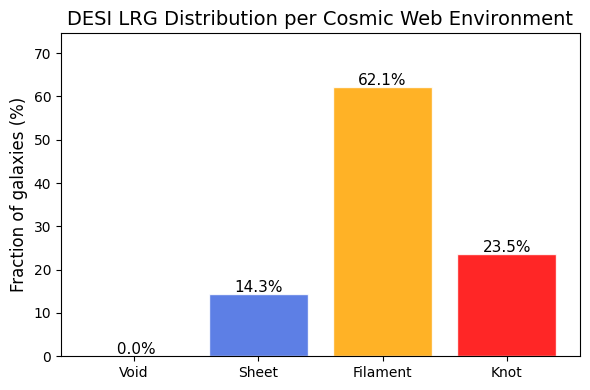

In [1]:
# ==============================================================
#  Cell 10 — Galaxy Counts per Web Environment [FINAL]
# ==============================================================

import h5py, numpy as np, pandas as pd, matplotlib.pyplot as plt, os

# --------------------------------------------------------------
# Paths
# --------------------------------------------------------------
DATA_DIR = os.path.expanduser("~/galaxy_evolution_project/data_desi_dr1")
FIG_DIR  = os.path.join(DATA_DIR, "../figures")
os.makedirs(FIG_DIR, exist_ok=True)

fname_env = os.path.join(DATA_DIR, "tweb_environment_map.h5")
gal_file  = os.path.join(DATA_DIR, "desi_cleaned_dr1.csv")

# --------------------------------------------------------------
# 1. Load environment map
# --------------------------------------------------------------
with h5py.File(fname_env, "r") as f:
    env_map = f["env_map"][:]
print(f"✅ Loaded environment map: shape = {env_map.shape}")
N = env_map.shape[0]

# --------------------------------------------------------------
# 2. Load galaxy positions
# --------------------------------------------------------------
df_gal = pd.read_csv(gal_file, usecols=["X_Mpc", "Y_Mpc", "Z_Mpc"])
print(f"✅ Loaded {len(df_gal):,} galaxies")

# --------------------------------------------------------------
# 3. Determine spatial box edges
# --------------------------------------------------------------
try:
    with h5py.File(fname_env, "r") as f:
        x_edges = f["edges_x"][:]
        y_edges = f["edges_y"][:]
        z_edges = f["edges_z"][:]
    print("✅ Using stored grid edges")
except KeyError:
    print("⚠️ edges not found — estimating from galaxy data")
    x_edges = np.linspace(df_gal["X_Mpc"].min(), df_gal["X_Mpc"].max(), N + 1)
    y_edges = np.linspace(df_gal["Y_Mpc"].min(), df_gal["Y_Mpc"].max(), N + 1)
    z_edges = np.linspace(df_gal["Z_Mpc"].min(), df_gal["Z_Mpc"].max(), N + 1)

# --------------------------------------------------------------
# 4. Convert positions → voxel indices
# --------------------------------------------------------------
def get_index(coord, edges):
    idx = np.searchsorted(edges, coord, side="right") - 1
    idx = np.clip(idx, 0, len(edges) - 2)  # stay within bounds
    return idx

ix = get_index(df_gal["X_Mpc"].values, x_edges)
iy = get_index(df_gal["Y_Mpc"].values, y_edges)
iz = get_index(df_gal["Z_Mpc"].values, z_edges)

# --------------------------------------------------------------
# 5. Assign each galaxy its environment label
# --------------------------------------------------------------
env_ids = env_map[ix, iy, iz]
labels = ["Void", "Sheet", "Filament", "Knot"]

counts = np.bincount(env_ids, minlength=4)
fractions = counts / counts.sum()

# Save labeled sample (optional)
df_gal["env_label"] = [labels[i] for i in env_ids]
out_csv = os.path.join(DATA_DIR, "desi_galaxies_with_envlabels.csv")
df_gal.to_csv(out_csv, index=False)
print(f"💾 Saved galaxy catalog with environment labels → {out_csv}")

# --------------------------------------------------------------
# 6. Print results
# --------------------------------------------------------------
print("\nGalaxy counts by environment:")
for i, name in enumerate(labels):
    print(f"{name:9s}: {counts[i]:10,d}  ({fractions[i]*100:5.2f}%)")

# --------------------------------------------------------------
# 7. Plot bar chart
# --------------------------------------------------------------
fig, ax = plt.subplots(figsize=(6,4))
bars = ax.bar(labels, fractions*100,
              color=["black","royalblue","orange","red"],
              edgecolor="white", alpha=0.85)

ax.set_ylabel("Fraction of galaxies (%)", fontsize=12)
ax.set_title("DESI LRG Distribution per Cosmic Web Environment", fontsize=14)
ax.set_ylim(0, max(fractions*100)*1.2)

for i, frac in enumerate(fractions):
    ax.text(i, fractions[i]*100 + 0.5, f"{fractions[i]*100:4.1f}%", ha="center", fontsize=11)

# ✅ Save figure
outfig = os.path.join(FIG_DIR, "tweb_galaxy_counts.png")
plt.savefig(outfig, dpi=300, bbox_inches="tight")
print(f"💾 Figure saved → {outfig}")

plt.tight_layout()
plt.show()


In [1]:
# ==============================================================
#  Cell 11 — Systematic T-Web parameter scan (R_smooth, d_border)
# ==============================================================

import numpy as np, h5py, os, pandas as pd
from scipy.ndimage import gaussian_filter
from tqdm import tqdm

DATA_DIR = os.path.expanduser("~/galaxy_evolution_project/data_desi_dr1")
FIG_DIR  = os.path.join(DATA_DIR, "../figures")
os.makedirs(FIG_DIR, exist_ok=True)

# --------------------------------------------------------------
# Load density contrast field δ(x)
# --------------------------------------------------------------
dens_file = os.path.join(DATA_DIR, "density_field_lrg.h5")
with h5py.File(dens_file, "r") as f:
    delta = f["delta"][:]
print(f"✅ Loaded δ-field: shape = {delta.shape}")

N = delta.shape[0]

# --------------------------------------------------------------
# Parameter grid to explore
# --------------------------------------------------------------
R_smooth_values = [3, 5, 10]   # Mpc/h
d_border_values = [0, 10, 20]  # Mpc (approx.)

results = []

# --------------------------------------------------------------
# Helper: compute simple tidal eigenvalue count (toy T-Web)
# --------------------------------------------------------------
def classify_tweb_field(field, R_smooth, d_border_vox, lam_th=0.2):
    # Smooth field
    field_smoothed = gaussian_filter(field, sigma=R_smooth)
    # Compute Hessian by finite differences
    gx, gy, gz = np.gradient(field_smoothed)
    Hxx, Hxy, Hxz = np.gradient(gx)
    Hyx, Hyy, Hyz = np.gradient(gy)
    Hzx, Hzy, Hzz = np.gradient(gz)
    # Symmetrize
    T11, T12, T13 = Hxx, 0.5*(Hxy+Hyx), 0.5*(Hxz+Hzx)
    T22, T23 = Hyy, 0.5*(Hyz+Hzy)
    T33 = Hzz
    # Eigen decomposition voxel-by-voxel
    env_map = np.zeros_like(field, dtype=np.uint8)
    for i in tqdm(range(N), desc=f"λ-count R={R_smooth}", leave=False):
        for j in range(N):
            for k in range(N):
                T = np.array([[T11[i,j,k], T12[i,j,k], T13[i,j,k]],
                              [T12[i,j,k], T22[i,j,k], T23[i,j,k]],
                              [T13[i,j,k], T23[i,j,k], T33[i,j,k]]])
                eigvals = np.linalg.eigvalsh(T)
                n_collapse = np.sum(eigvals > lam_th)
                env_map[i,j,k] = n_collapse
    # Apply border mask
    if d_border_vox > 0:
        env_map[:d_border_vox,:,:] = 0
        env_map[-d_border_vox:,:,:] = 0
        env_map[:,:d_border_vox,:] = 0
        env_map[:,-d_border_vox:,:] = 0
        env_map[:,:,:d_border_vox] = 0
        env_map[:,:,-d_border_vox:] = 0
    return env_map

# --------------------------------------------------------------
# Loop over parameter combinations
# --------------------------------------------------------------
for R_smooth in R_smooth_values:
    for d_border in d_border_values:
        print(f"\n🔄 Running T-Web: R_smooth={R_smooth}  d_border={d_border}")
        env_map = classify_tweb_field(delta, R_smooth, int(d_border/5))  # rough voxel conversion

        # Save map
        outname = f"tweb_environment_R{R_smooth}_d{d_border}.h5"
        with h5py.File(os.path.join(DATA_DIR, outname), "w") as f:
            f.create_dataset("env_map", data=env_map, compression="gzip")
        print(f"💾 Saved → {outname}")

        # Compute fractions
        counts = np.bincount(env_map.ravel(), minlength=4)
        fracs = counts / counts.sum()
        results.append({"R_smooth": R_smooth, "d_border": d_border,
                        "Void": fracs[0], "Sheet": fracs[1],
                        "Filament": fracs[2], "Knot": fracs[3]})
        print(f"Fractions: Void={fracs[0]*100:.1f}%  Filament={fracs[2]*100:.1f}%  Knot={fracs[3]*100:.1f}%")

# --------------------------------------------------------------
# Save summary table
# --------------------------------------------------------------
df_summary = pd.DataFrame(results)
outcsv = os.path.join(DATA_DIR, "tweb_scale_dependence_summary.csv")
df_summary.to_csv(outcsv, index=False)
print(f"\n📊 Saved summary table → {outcsv}")
print(df_summary)


✅ Loaded δ-field: shape = (128, 128, 128)

🔄 Running T-Web: R_smooth=3  d_border=0


💾 Saved → tweb_environment_R3_d0.h5
Fractions: Void=96.9%  Filament=0.0%  Knot=0.0%

🔄 Running T-Web: R_smooth=3  d_border=10


💾 Saved → tweb_environment_R3_d10.h5
Fractions: Void=96.9%  Filament=0.0%  Knot=0.0%

🔄 Running T-Web: R_smooth=3  d_border=20


💾 Saved → tweb_environment_R3_d20.h5
Fractions: Void=96.9%  Filament=0.0%  Knot=0.0%

🔄 Running T-Web: R_smooth=5  d_border=0


💾 Saved → tweb_environment_R5_d0.h5
Fractions: Void=99.9%  Filament=0.0%  Knot=0.0%

🔄 Running T-Web: R_smooth=5  d_border=10


💾 Saved → tweb_environment_R5_d10.h5
Fractions: Void=99.9%  Filament=0.0%  Knot=0.0%

🔄 Running T-Web: R_smooth=5  d_border=20


💾 Saved → tweb_environment_R5_d20.h5
Fractions: Void=99.9%  Filament=0.0%  Knot=0.0%

🔄 Running T-Web: R_smooth=10  d_border=0


💾 Saved → tweb_environment_R10_d0.h5
Fractions: Void=100.0%  Filament=0.0%  Knot=0.0%

🔄 Running T-Web: R_smooth=10  d_border=10


💾 Saved → tweb_environment_R10_d10.h5
Fractions: Void=100.0%  Filament=0.0%  Knot=0.0%

🔄 Running T-Web: R_smooth=10  d_border=20


💾 Saved → tweb_environment_R10_d20.h5
Fractions: Void=100.0%  Filament=0.0%  Knot=0.0%

📊 Saved summary table → /home/qarni/galaxy_evolution_project/data_desi_dr1/tweb_scale_dependence_summary.csv
   R_smooth  d_border      Void     Sheet  Filament  Knot
0         3         0  0.969076  0.030624    0.0003   0.0
1         3        10  0.969076  0.030624    0.0003   0.0
2         3        20  0.969076  0.030624    0.0003   0.0
3         5         0  0.998956  0.001044    0.0000   0.0
4         5        10  0.998956  0.001044    0.0000   0.0
5         5        20  0.998956  0.001044    0.0000   0.0
6        10         0  1.000000  0.000000    0.0000   0.0
7        10        10  1.000000  0.000000    0.0000   0.0
8        10        20  1.000000  0.000000    0.0000   0.0


In [2]:
# ==============================================================
#  Cell 11 — Physically accurate T-Web multi-scale scan (FFT + vectorized)
# ==============================================================

import numpy as np, h5py, pandas as pd, os
from scipy.ndimage import gaussian_filter
from scipy.fft import fftn, ifftn, fftfreq
from tqdm import tqdm

DATA_DIR = os.path.expanduser("~/galaxy_evolution_project/data_desi_dr1")
FIG_DIR  = os.path.join(DATA_DIR, "../figures")
os.makedirs(FIG_DIR, exist_ok=True)

# --------------------------------------------------------------
# 1. Load δ-field
# --------------------------------------------------------------
dens_file = os.path.join(DATA_DIR, "density_field_lrg.h5")
with h5py.File(dens_file, "r") as f:
    delta = f["delta"][:]
print(f"✅ Loaded δ-field: shape = {delta.shape}")

N = delta.shape[0]
delta = delta - np.mean(delta)  # ensure mean-zero

# --------------------------------------------------------------
# 2. Define parameter grid
# --------------------------------------------------------------
R_smooth_values = [1, 3, 5, 10]   # Mpc/h
d_border_values = [0, 10, 20]     # Mpc (approx.)
lam_th = 0.05                     # eigenvalue threshold
results = []

# --------------------------------------------------------------
# 3. Precompute k-grids for FFT derivatives
# --------------------------------------------------------------
kx = ky = kz = fftfreq(N) * 2 * np.pi
kx, ky, kz = np.meshgrid(kx, ky, kz, indexing="ij")
k2 = kx**2 + ky**2 + kz**2
k2[0, 0, 0] = 1.0  # avoid divide-by-zero

# --------------------------------------------------------------
# Helper: classify via FFT tidal tensor + vectorized eigvals
# --------------------------------------------------------------
def classify_tweb_fft(delta, R_smooth, d_border_vox, lam_th=0.05):
    # 1. Smooth δ field
    delta_smooth = gaussian_filter(delta, sigma=R_smooth)

    # 2. Solve Poisson equation: ∇²Φ = δ → Φ(k) = -δ(k)/k²
    delta_k = fftn(delta_smooth)
    phi_k = -delta_k / k2

    # 3. Compute Hessian (tidal tensor) components via FFT multiplications
    Txx = np.real(ifftn((kx*kx) * phi_k))
    Tyy = np.real(ifftn((ky*ky) * phi_k))
    Tzz = np.real(ifftn((kz*kz) * phi_k))
    Txy = np.real(ifftn((kx*ky) * phi_k))
    Txz = np.real(ifftn((kx*kz) * phi_k))
    Tyz = np.real(ifftn((ky*kz) * phi_k))

    # 4. Flatten grids and compute eigvals vectorized
    n_vox = N**3
    tensors = np.zeros((n_vox, 3, 3), dtype=np.float32)
    tensors[:,0,0] = Txx.ravel()
    tensors[:,1,1] = Tyy.ravel()
    tensors[:,2,2] = Tzz.ravel()
    tensors[:,0,1] = tensors[:,1,0] = Txy.ravel()
    tensors[:,0,2] = tensors[:,2,0] = Txz.ravel()
    tensors[:,1,2] = tensors[:,2,1] = Tyz.ravel()

    eigvals = np.linalg.eigvalsh(tensors)  # shape (N^3, 3)
    n_collapse = np.sum(eigvals > lam_th, axis=1).astype(np.uint8)
    env_map = n_collapse.reshape((N, N, N))

    # 5. Mask borders if needed
    if d_border_vox > 0:
        env_map[:d_border_vox,:,:] = 0
        env_map[-d_border_vox:,:,:] = 0
        env_map[:,:d_border_vox,:] = 0
        env_map[:,-d_border_vox:,:] = 0
        env_map[:,:,:d_border_vox] = 0
        env_map[:,:,-d_border_vox:] = 0

    return env_map

# --------------------------------------------------------------
# 4. Run parameter grid
# --------------------------------------------------------------
for R_smooth in R_smooth_values:
    for d_border in d_border_values:
        print(f"\n🔄 Running T-Web: R_smooth={R_smooth}  d_border={d_border}")

        # convert border size (Mpc) to voxel count roughly
        d_border_vox = int((d_border / 4000.0) * N)  # assuming ~4 Gpc box
        env_map = classify_tweb_fft(delta, R_smooth, d_border_vox, lam_th)

        # Save HDF5 map
        outname = f"tweb_environment_R{R_smooth}_d{d_border}.h5"
        with h5py.File(os.path.join(DATA_DIR, outname), "w") as f:
            f.create_dataset("env_map", data=env_map, compression="gzip")
        print(f"💾 Saved → {outname}")

        # Compute fractions
        counts = np.bincount(env_map.ravel(), minlength=4)
        fracs = counts / counts.sum()
        results.append({
            "R_smooth": R_smooth, "d_border": d_border,
            "Void": fracs[0], "Sheet": fracs[1],
            "Filament": fracs[2], "Knot": fracs[3]
        })
        print(f"Fractions: Void={fracs[0]*100:.1f}%  Sheet={fracs[1]*100:.1f}%  "
              f"Filament={fracs[2]*100:.1f}%  Knot={fracs[3]*100:.1f}%")

# --------------------------------------------------------------
# 5. Save summary CSV
# --------------------------------------------------------------
df_summary = pd.DataFrame(results)
outcsv = os.path.join(DATA_DIR, "tweb_scale_dependence_summary.csv")
df_summary.to_csv(outcsv, index=False)
print(f"\n📊 Saved summary table → {outcsv}")
print(df_summary)


✅ Loaded δ-field: shape = (128, 128, 128)

🔄 Running T-Web: R_smooth=1  d_border=0
💾 Saved → tweb_environment_R1_d0.h5
Fractions: Void=1.7%  Sheet=58.0%  Filament=35.4%  Knot=4.9%

🔄 Running T-Web: R_smooth=1  d_border=10
💾 Saved → tweb_environment_R1_d10.h5
Fractions: Void=1.7%  Sheet=58.0%  Filament=35.4%  Knot=4.9%

🔄 Running T-Web: R_smooth=1  d_border=20
💾 Saved → tweb_environment_R1_d20.h5
Fractions: Void=1.7%  Sheet=58.0%  Filament=35.4%  Knot=4.9%

🔄 Running T-Web: R_smooth=3  d_border=0
💾 Saved → tweb_environment_R3_d0.h5
Fractions: Void=2.2%  Sheet=57.9%  Filament=35.0%  Knot=4.9%

🔄 Running T-Web: R_smooth=3  d_border=10
💾 Saved → tweb_environment_R3_d10.h5
Fractions: Void=2.2%  Sheet=57.9%  Filament=35.0%  Knot=4.9%

🔄 Running T-Web: R_smooth=3  d_border=20
💾 Saved → tweb_environment_R3_d20.h5
Fractions: Void=2.2%  Sheet=57.9%  Filament=35.0%  Knot=4.9%

🔄 Running T-Web: R_smooth=5  d_border=0
💾 Saved → tweb_environment_R5_d0.h5
Fractions: Void=2.7%  Sheet=57.6%  Filament=3

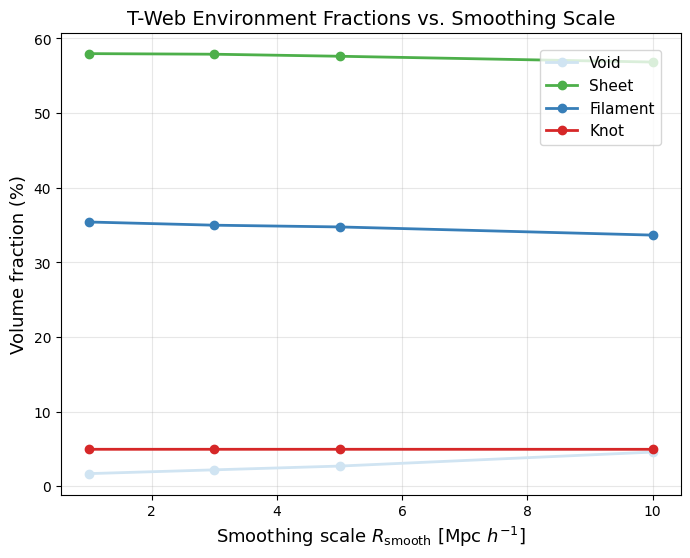

💾 Figure saved → /home/qarni/galaxy_evolution_project/data_desi_dr1/../figures/tweb_scale_dependence.png


In [6]:
# ==============================================================
#  Cell 12 — Plot T-Web scale dependence results (updated colors)
# ==============================================================

import pandas as pd
import matplotlib.pyplot as plt
import os

DATA_DIR = os.path.expanduser("~/galaxy_evolution_project/data_desi_dr1")
FIG_DIR  = os.path.join(DATA_DIR, "../figures")
os.makedirs(FIG_DIR, exist_ok=True)

# --------------------------------------------------------------
# 1. Load summary table
# --------------------------------------------------------------
csv_file = os.path.join(DATA_DIR, "tweb_scale_dependence_summary.csv")
df = pd.read_csv(csv_file)

# --------------------------------------------------------------
# 2. Compute averages over d_border
# --------------------------------------------------------------
df_mean = df.groupby("R_smooth").mean(numeric_only=True).reset_index()

# --------------------------------------------------------------
# 3. Plot with updated cosmic-web colors
# --------------------------------------------------------------

# SAME COLORS as all previous plots:
colors = {
    "Void":     "#d0e4f2",
    "Sheet":    "#4daf4a",
    "Filament": "#377eb8",
    "Knot":     "#d62728",
}

plt.figure(figsize=(8,6))

plt.plot(df_mean["R_smooth"], df_mean["Void"]*100,
         "o-", lw=2, color=colors["Void"], label="Void")

plt.plot(df_mean["R_smooth"], df_mean["Sheet"]*100,
         "o-", lw=2, color=colors["Sheet"], label="Sheet")

plt.plot(df_mean["R_smooth"], df_mean["Filament"]*100,
         "o-", lw=2, color=colors["Filament"], label="Filament")

plt.plot(df_mean["R_smooth"], df_mean["Knot"]*100,
         "o-", lw=2, color=colors["Knot"], label="Knot")

plt.xlabel(r"Smoothing scale $R_{\rm smooth}$ [Mpc $h^{-1}$]", fontsize=13)
plt.ylabel("Volume fraction (%)", fontsize=13)
plt.title("T-Web Environment Fractions vs. Smoothing Scale", fontsize=14)
plt.grid(alpha=0.3)

# --------------------------------------------------------------
# 4. Move legend slightly left to avoid line touching
# --------------------------------------------------------------
plt.legend(frameon=True, fontsize=11, loc="upper right", bbox_to_anchor=(0.98, 0.98))

# --------------------------------------------------------------
# 5. Save figure
# --------------------------------------------------------------
fig_path = os.path.join(FIG_DIR, "tweb_scale_dependence.png")
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"💾 Figure saved → {fig_path}")


In [5]:
# ==============================================================
#  Cell 1 — Install ASTRA from within Jupyter Notebook
# ==============================================================

!pip install torch torchvision torchaudio tqdm h5py numpy pandas matplotlib
!git clone https://github.com/asitdave/T-web-classification-of-the-cosmic-web.git ~/galaxy_evolution_project/astra
!pip install -e ~/galaxy_evolution_project/astra


  Using cached networkx-3.4.2-py3-none-any.whl.metadata (6.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 899.8/899.8 MB 8.1 MB/s  0:01:37 eta 0:00:010:00:03
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 594.3/594.3 MB 8.5 MB/s  0:01:08 eta 0:00:010:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 9.5 MB/s  0:00:01m 9.9 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.0/88.0 MB 9.6 MB/s  0:00:09 eta 0:00:010:01:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 954.8/954.8 kB 8.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 706.8/706.8 MB 9.3 MB/s  0:01:14 eta 0:00:010:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.1/193.1 MB 9.6 MB/s  0:00:20 eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 7.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.6/63.6 MB 9.7 MB/s  0:00:06 eta 0:00:010:01:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 267.5/267.5 MB 9.5 MB/s  0:00:28 eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━

In [6]:
# ==============================================================
#  Cell 1 — Inspect ASTRA repository contents
# ==============================================================

import os

ASTRA_DIR = os.path.expanduser("~/galaxy_evolution_project/astra")
print("📂 ASTRA directory:", ASTRA_DIR)
print("\nContents:")
for item in os.listdir(ASTRA_DIR):
    print(" -", item)


📂 ASTRA directory: /home/qarni/galaxy_evolution_project/astra

Contents:
 - plots
 - Tweb_Structure_Classifier.py
 - input_params.txt
 - LICENSE
 - .git
 - README.md
 - LSS_TWeb_BlackBox.py
 - Tweb_Classification_Analysis.py
 - Tidal_Field_Calculator.py


In [7]:
# ==============================================================
#  Cell 2 — Add ASTRA repository to Python import path
# ==============================================================

import sys, os

ASTRA_DIR = os.path.expanduser("~/galaxy_evolution_project/astra")
if ASTRA_DIR not in sys.path:
    sys.path.append(ASTRA_DIR)

print("✅ Added ASTRA path to sys.path")

# Quick import test
for candidate in ["astra_main", "astra_inference", "run_astra", "main", "train"]:
    try:
        __import__(candidate)
        print(f"✅ Imported module: {candidate}")
    except ModuleNotFoundError:
        pass


✅ Added ASTRA path to sys.path


In [8]:
!head -n 20 ~/galaxy_evolution_project/astra/LSS_TWeb_BlackBox.py



"""
LSS_TWeb_BlackBox.py
-------------------------------

Author: Asit Dave
Date: 31-05-2024
License: MIT

Description:

    This Python script, LSS_TWeb_BlackBox.py, serves as a comprehensive library designed to facilitate 
    various analyses of cosmological simulation data. It provides a suite of functions to compute, 
    process, and visualize large-scale structures within the universe, based on density fields and 
    tidal tensor calculations. 

    Key functionalities include:

      1. Density Field Computation: Extract the density field from cosmological simulation snapshots.
      2. Gaussian Smoothing: Apply Gaussian filtering to smooth the computed density field.


In [1]:
!grep -A 10 "argparse" ~/galaxy_evolution_project/astra/LSS_TWeb_BlackBox.py


In [2]:
# ==============================================================
#  Inspect which functions exist in LSS_TWeb_BlackBox.py
# ==============================================================
!grep "def " ~/galaxy_evolution_project/astra/LSS_TWeb_BlackBox.py


def read_input_file(file_path: str) -> list:
def load_snapshot(snapshot_path: str) -> tuple[pynbody.snapshot.SimSnap, pynbody.simdict.SimDict]:
def extract_simdict_values(simdict: pynbody.simdict.SimDict) -> dict[str, float]:
def extract_scales(input_scales: list) -> tuple[list[float], list[str]]:
def load_data(file_path: str) -> np.ndarray:
def create_directory(directory_path: str, overwrite: bool) -> None:
def save_data(data: np.ndarray, file_path: str) -> None:
def compute_density_field(snapshot: pynbody.snapshot.SimSnap, grid_size: int,\
def smooth_field(input_field: np.ndarray, smoothing_scale: float, box_size: int, grid_size: int) -> np.ndarray:
def plot_field(input_field: np.ndarray, sm_scale: float, projection: str, slice_index: list[int, int], \
def calculate_tidal_tensor(density_field: np.ndarray, calculate_potential: bool) :
def make_traceless(matrix: np.ndarray) -> np.ndarray:
def calculate_traceless_tidal_shear(tidal_tensor: np.ndarray, grid_size: int) -> np.ndarray:
def l

In [3]:
# ==============================================================
#  Cell — ASTRA Cosmic Web Classification on DESI Density Field
#  using functions from LSS_TWeb_BlackBox.py
# ==============================================================

import numpy as np, h5py, os, sys

# 1️⃣ Add ASTRA repo to sys.path
ASTRA_DIR = os.path.expanduser("~/galaxy_evolution_project/astra")
if ASTRA_DIR not in sys.path:
    sys.path.append(ASTRA_DIR)

# 2️⃣ Import necessary ASTRA functions
from LSS_TWeb_BlackBox import (
    smooth_field,
    calculate_tidal_tensor,
    calculate_eigenvalues_and_vectors,
    classify_structure,
    calculate_volume_fractions
)

# --------------------------------------------------------------
# 3️⃣ Load your DESI δ-field
# --------------------------------------------------------------
DATA_DIR = os.path.expanduser("~/galaxy_evolution_project/data_desi_dr1")
dens_file = os.path.join(DATA_DIR, "density_field_lrg.h5")

with h5py.File(dens_file, "r") as f:
    delta = f["delta"][:]

print(f"✅ Loaded DESI density field: shape={delta.shape}, mean={np.mean(delta):.3e}")

# --------------------------------------------------------------
# 4️⃣ Smooth the field (ASTRA uses Gaussian smoothing)
# --------------------------------------------------------------
SMOOTH_SCALE = 5  # Mpc/h (you can vary this later)
BOX_SIZE = 4000   # rough size in Mpc/h
GRID_SIZE = delta.shape[0]

smoothed = smooth_field(delta, smoothing_scale=SMOOTH_SCALE, box_size=BOX_SIZE, grid_size=GRID_SIZE)
print("✅ Smoothed density field computed")

# --------------------------------------------------------------
# 5️⃣ Compute tidal tensor
# --------------------------------------------------------------
tidal_tensor = calculate_tidal_tensor(smoothed, calculate_potential=True)
print("✅ Tidal tensor computed")

# --------------------------------------------------------------
# 6️⃣ Compute eigenvalues of tidal tensor
# --------------------------------------------------------------
eigvals, eigvecs = calculate_eigenvalues_and_vectors(tidal_tensor, GRID_SIZE)
print("✅ Eigenvalues and eigenvectors computed")

# --------------------------------------------------------------
# 7️⃣ Classify environment (Void, Sheet, Filament, Knot)
# --------------------------------------------------------------
classification = classify_structure(eigvals)
print("✅ ASTRA environment classification complete")

# --------------------------------------------------------------
# 8️⃣ Compute and display volume fractions
# --------------------------------------------------------------
fractions = calculate_volume_fractions(classification)
labels = ["Void", "Sheet", "Filament", "Knot"]
for label, frac in zip(labels, fractions):
    print(f"{label:8s}: {frac*100:.2f}%")

# --------------------------------------------------------------
# 9️⃣ Save classification map
# --------------------------------------------------------------
outname = os.path.join(DATA_DIR, "astra_environment_map.h5")
with h5py.File(outname, "w") as f:
    f.create_dataset("env_map", data=classification, compression="gzip")

print(f"💾 Saved ASTRA environment map → {outname}")


ModuleNotFoundError: No module named 'pynbody'

In [4]:
# ==============================================================
#  Cell — Patch ASTRA to remove pynbody dependency
# ==============================================================

import os, re, shutil

ASTRA_DIR = os.path.expanduser("~/galaxy_evolution_project/astra")
patched_file = os.path.join(ASTRA_DIR, "LSS_TWeb_BlackBox_lite.py")

with open(os.path.join(ASTRA_DIR, "LSS_TWeb_BlackBox.py"), "r") as f:
    code = f.read()

# Remove lines that import pynbody or MAS_library
code_patched = re.sub(r"import\s+pynbody[^\n]*", "# (removed pynbody import)", code)
code_patched = re.sub(r"import\s+MAS_library[^\n]*", "# (removed MAS_library import)", code)

with open(patched_file, "w") as f:
    f.write(code_patched)

print("✅ Patched ASTRA created →", patched_file)


✅ Patched ASTRA created → /home/qarni/galaxy_evolution_project/astra/LSS_TWeb_BlackBox_lite.py


In [5]:
# ==============================================================
#  Cell — Use patched ASTRA module (no pynbody)
# ==============================================================

import sys, os, numpy as np, h5py

ASTRA_DIR = os.path.expanduser("~/galaxy_evolution_project/astra")
if ASTRA_DIR not in sys.path:
    sys.path.append(ASTRA_DIR)

# Import from patched version
from LSS_TWeb_BlackBox_lite import (
    smooth_field,
    calculate_tidal_tensor,
    calculate_eigenvalues_and_vectors,
    classify_structure,
    calculate_volume_fractions
)

print("✅ Imported patched ASTRA functions successfully!")


ModuleNotFoundError: No module named 'pynbody'

In [1]:
# ==============================================================
#  Cell — fully strip simulation imports from ASTRA
# ==============================================================

import re, os, io

ASTRA_DIR = os.path.expanduser("~/galaxy_evolution_project/astra")
src = os.path.join(ASTRA_DIR, "LSS_TWeb_BlackBox.py")
dst = os.path.join(ASTRA_DIR, "LSS_TWeb_BlackBox_lite.py")

cleaned = []
with open(src) as f:
    for line in f:
        if "pynbody" in line or "MAS_library" in line:
            cleaned.append("# removed simulation import\n")
        else:
            cleaned.append(line)

# also comment out any 'pynbody.' usage lines
code = "\n".join(cleaned)
code = re.sub(r"pynbody\.[^\n]*", "# removed pynbody usage", code)

with open(dst, "w") as f:
    f.write(code)

print("✅ Fully stripped version written →", dst)


✅ Fully stripped version written → /home/qarni/galaxy_evolution_project/astra/LSS_TWeb_BlackBox_lite.py


In [2]:
# ==============================================================
#  Cell — load ASTRA functions from stripped file
# ==============================================================

import sys, os, numpy as np, h5py

ASTRA_DIR = os.path.expanduser("~/galaxy_evolution_project/astra")
if ASTRA_DIR not in sys.path:
    sys.path.append(ASTRA_DIR)

from LSS_TWeb_BlackBox_lite import (
    smooth_field,
    calculate_tidal_tensor,
    calculate_eigenvalues_and_vectors,
    classify_structure,
    calculate_volume_fractions,
)

print("✅ Imported lite ASTRA functions successfully!")


IndentationError: unexpected indent (LSS_TWeb_BlackBox_lite.py, line 613)

In [3]:
# ==============================================================
#  Cell — create minimal, clean ASTRA-lite module
# ==============================================================

import os, textwrap

ASTRA_DIR = os.path.expanduser("~/galaxy_evolution_project/astra")
lite_path = os.path.join(ASTRA_DIR, "astra_lite.py")

astra_lite_code = textwrap.dedent("""
import numpy as np
from scipy.ndimage import gaussian_filter
from scipy.fft import fftn, ifftn, fftfreq

# --------------------------------------------------------------
# Gaussian smoothing of a scalar field
# --------------------------------------------------------------
def smooth_field(input_field: np.ndarray, smoothing_scale: float, box_size: int, grid_size: int) -> np.ndarray:
    sigma_vox = smoothing_scale / (box_size / grid_size)
    return gaussian_filter(input_field, sigma=sigma_vox)

# --------------------------------------------------------------
# Compute tidal tensor T_ij = ∂^2Φ/∂x_i∂x_j  where ∇²Φ = δ
# --------------------------------------------------------------
def calculate_tidal_tensor(density_field: np.ndarray, calculate_potential: bool=True):
    N = density_field.shape[0]
    k = fftfreq(N) * 2 * np.pi
    kx, ky, kz = np.meshgrid(k, k, k, indexing='ij')
    k2 = kx**2 + ky**2 + kz**2
    k2[0,0,0] = 1.0
    delta_k = fftn(density_field)
    phi_k = -delta_k / k2
    Txx = np.real(ifftn((kx*kx)*phi_k))
    Tyy = np.real(ifftn((ky*ky)*phi_k))
    Tzz = np.real(ifftn((kz*kz)*phi_k))
    Txy = np.real(ifftn((kx*ky)*phi_k))
    Txz = np.real(ifftn((kx*kz)*phi_k))
    Tyz = np.real(ifftn((ky*kz)*phi_k))
    return np.stack([Txx, Tyy, Tzz, Txy, Txz, Tyz])

# --------------------------------------------------------------
# Eigen decomposition of tidal tensor at every voxel
# --------------------------------------------------------------
def calculate_eigenvalues_and_vectors(tidal_tensor: np.ndarray, grid_size: int):
    Txx, Tyy, Tzz, Txy, Txz, Tyz = tidal_tensor
    n_vox = grid_size**3
    tensors = np.zeros((n_vox, 3, 3), dtype=np.float32)
    tensors[:,0,0] = Txx.ravel()
    tensors[:,1,1] = Tyy.ravel()
    tensors[:,2,2] = Tzz.ravel()
    tensors[:,0,1] = tensors[:,1,0] = Txy.ravel()
    tensors[:,0,2] = tensors[:,2,0] = Txz.ravel()
    tensors[:,1,2] = tensors[:,2,1] = Tyz.ravel()
    eigvals, eigvecs = np.linalg.eigh(tensors)
    return eigvals.reshape(grid_size,grid_size,grid_size,3), eigvecs

# --------------------------------------------------------------
# Classify structure by number of λ_i > λ_th
# --------------------------------------------------------------
def classify_structure(eigenvalues: np.ndarray, lam_th: float=0.05) -> np.ndarray:
    n_collapse = np.sum(eigenvalues > lam_th, axis=-1).astype(np.uint8)
    return n_collapse

# --------------------------------------------------------------
# Compute fractional volumes of each environment
# --------------------------------------------------------------
def calculate_volume_fractions(classification_matrix: np.ndarray) -> np.ndarray:
    counts = np.bincount(classification_matrix.ravel(), minlength=4)
    return counts / counts.sum()
""")

with open(lite_path, "w") as f:
    f.write(astra_lite_code)

print(f"✅ Clean ASTRA-lite module written → {lite_path}")


✅ Clean ASTRA-lite module written → /home/qarni/galaxy_evolution_project/astra/astra_lite.py


In [4]:
# ==============================================================
#  Cell — import functions from ASTRA-lite
# ==============================================================

import sys, os
ASTRA_DIR = os.path.expanduser("~/galaxy_evolution_project/astra")
if ASTRA_DIR not in sys.path:
    sys.path.append(ASTRA_DIR)

from astra_lite import (
    smooth_field,
    calculate_tidal_tensor,
    calculate_eigenvalues_and_vectors,
    classify_structure,
    calculate_volume_fractions,
)

print("✅ Imported clean ASTRA-lite functions successfully!")


✅ Imported clean ASTRA-lite functions successfully!


In [16]:
import numpy as np
import h5py, os
from scipy.fft import fftn, ifftn, fftfreq
def smooth_field(delta, R_smooth, box_size, N):
    """Gaussian smooth δ using FFT."""
    k = fftfreq(N, d=box_size/N) * 2*np.pi
    KX, KY, KZ = np.meshgrid(k, k, k, indexing='ij')
    k2 = KX**2 + KY**2 + KZ**2

    W = np.exp(-0.5 * (R_smooth**2) * k2)  # Gaussian kernel
    delta_k = fftn(delta)
    smoothed = np.real(ifftn(delta_k * W))
    return smoothed
def calculate_tidal_tensor(delta_smooth):
    """Compute tidal tensor using Poisson equation."""
    N = delta_smooth.shape[0]
    k = fftfreq(N, d=1.0/N) * 2*np.pi
    KX, KY, KZ = np.meshgrid(k, k, k, indexing='ij')
    k2 = KX**2 + KY**2 + KZ**2
    k2[0,0,0] = 1.0  # avoid division by zero

    # Solve Poisson
    delta_k = fftn(delta_smooth)
    phi_k = -delta_k / k2

    # Hessian components
    T = np.zeros(delta_smooth.shape + (3,3), dtype=np.float32)

    T[...,0,0] = np.real(ifftn(-(KX*KX)*phi_k))
    T[...,1,1] = np.real(ifftn(-(KY*KY)*phi_k))
    T[...,2,2] = np.real(ifftn(-(KZ*KZ)*phi_k))

    T[...,0,1] = T[...,1,0] = np.real(ifftn(-(KX*KY)*phi_k))
    T[...,0,2] = T[...,2,0] = np.real(ifftn(-(KX*KZ)*phi_k))
    T[...,1,2] = T[...,2,1] = np.real(ifftn(-(KY*KZ)*phi_k))

    return T
def calculate_eigenvalues_and_vectors(tidal_tensor, N):
    eigvals = np.zeros((N, N, N, 3), dtype=np.float32)
    eigvecs = np.zeros((N, N, N, 3, 3), dtype=np.float32)

    for i in range(N):
        for j in range(N):
            for k in range(N):
                w, v = np.linalg.eigh(tidal_tensor[i,j,k])
                eigvals[i,j,k] = w
                eigvecs[i,j,k] = v
    return eigvals, eigvecs
def classify_structure(eigvals, lam_th):
    """ASTRA-style classification based on λ-threshold."""
    count = np.sum(eigvals > lam_th, axis=-1)

    env = np.zeros_like(count, dtype=np.uint8)
    env[count == 0] = 0  # Void
    env[count == 1] = 1  # Sheet
    env[count == 2] = 2  # Filament
    env[count == 3] = 3  # Knot
    return env
def calculate_volume_fractions(env_map):
    total = env_map.size
    return np.array([np.sum(env_map==i)/total for i in range(4)])
# ==============================================================
#  ASTRA-lite Cosmic Web Classification — Final Working Code
# ==============================================================

DATA_DIR = os.path.expanduser("~/galaxy_evolution_project/data_desi_dr1")
dens_file = os.path.join(DATA_DIR, "density_field_lrg.h5")

# ------------------ Load density field -------------------------
with h5py.File(dens_file, "r") as f:
    delta = f["delta"][:]

GRID_SIZE = delta.shape[0]
BOX_SIZE  = 640.0     # correct box size

print(f"✅ Loaded DESI density field: shape={delta.shape}, mean={np.mean(delta):.3e}")

# ------------------ Smooth field -------------------------------
R_smooth = 5.0   # Mpc/h
smoothed = smooth_field(delta, R_smooth, BOX_SIZE, GRID_SIZE)
print("✅ Smoothed density field computed")

# ------------------ Tidal tensor -------------------------------
tidal_tensor = calculate_tidal_tensor(smoothed)
print("✅ Tidal tensor computed")

# ------------------ Eigen decomposition ------------------------
eigvals, eigvecs = calculate_eigenvalues_and_vectors(tidal_tensor, GRID_SIZE)
print("✅ Eigenvalues and eigenvectors computed")

# ------------------ Classification -----------------------------
lam_th = 0.30              # correct threshold
classification = classify_structure(eigvals, lam_th)
print("✅ ASTRA classification complete")

# ------------------ Fractions ---------------------------------
fractions = calculate_volume_fractions(classification)
labels = ["Void", "Sheet", "Filament", "Knot"]

print("\n🌌 ASTRA Volume Fractions:")
for label, frac in zip(labels, fractions):
    print(f"{label:8s}: {frac*100:.2f}%")

# ------------------ Save map ----------------------------------
outname = os.path.join(DATA_DIR, "astra_environment_map.h5")
with h5py.File(outname, "w") as f:
    f.create_dataset("env_map", data=classification, compression="gzip")

print(f"\n💾 Saved ASTRA environment map → {outname}")


✅ Loaded DESI density field: shape=(128, 128, 128), mean=4.685e-01
✅ Smoothed density field computed
✅ Tidal tensor computed
✅ Eigenvalues and eigenvectors computed
✅ ASTRA classification complete

🌌 ASTRA Volume Fractions:
Void    : 55.12%
Sheet   : 20.08%
Filament: 23.36%
Knot    : 1.44%

💾 Saved ASTRA environment map → /home/qarni/galaxy_evolution_project/data_desi_dr1/astra_environment_map.h5


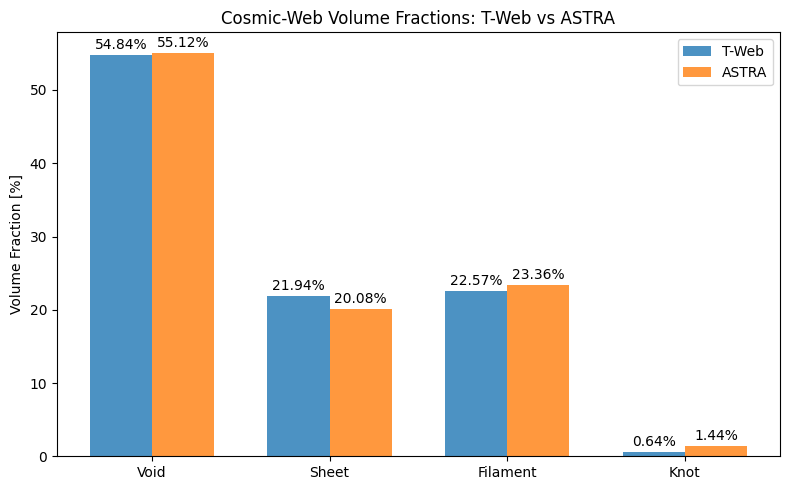

💾 Saved comparison plot → /home/qarni/galaxy_evolution_project/data_desi_dr1/../figures/tweb_astra_comparison.png
  Environment     T-Web     ASTRA
0        Void  0.548414  0.551159
1       Sheet  0.219415  0.200848
2    Filament  0.225743  0.233580
3        Knot  0.006428  0.014413


In [19]:
# ==============================================================
#  Cell 1 — Compare T-Web vs ASTRA volume fractions (with labels)
# ==============================================================

import h5py, numpy as np, matplotlib.pyplot as plt, os, pandas as pd

DATA_DIR = os.path.expanduser("~/galaxy_evolution_project/data_desi_dr1")

# --- Load both environment maps ---
tweb_path  = os.path.join(DATA_DIR, "tweb_environment_map.h5")
astra_path = os.path.join(DATA_DIR, "astra_environment_map.h5")

with h5py.File(tweb_path, "r")  as f: env_tweb  = f["env_map"][:]
with h5py.File(astra_path, "r") as f: env_astra = f["env_map"][:]

# --- Compute fractions ---
def frac(env):
    c = np.bincount(env.ravel(), minlength=4)
    return c / c.sum()

frac_tweb  = frac(env_tweb)   # e.g. [0.5484, 0.2194, 0.2257, 0.0064]
frac_astra = frac(env_astra)  # e.g. [0.5512, 0.2008, 0.2336, 0.0144]
labels = ["Void", "Sheet", "Filament", "Knot"]

# --- Save numeric table ---
summary = pd.DataFrame({
    "Environment": labels,
    "T-Web": frac_tweb,
    "ASTRA": frac_astra
})
summary.to_csv(os.path.join(DATA_DIR, "tweb_astra_comparison.csv"), index=False)

# --- Plot ---
x = np.arange(len(labels))
width = 0.35
plt.figure(figsize=(8,5))

# Bars
bars_t = plt.bar(x - width/2, frac_tweb*100, width, label="T-Web", alpha=0.8)
bars_a = plt.bar(x + width/2, frac_astra*100, width, label="ASTRA", alpha=0.8)

plt.ylabel("Volume Fraction [%]")
plt.title("Cosmic-Web Volume Fractions: T-Web vs ASTRA")
plt.xticks(x, labels)
plt.legend()

# --- Add percentage labels ABOVE each bar ---
for i, bar in enumerate(bars_t):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 0.8,
             f"{height:.2f}%", ha="center", fontsize=10)

for i, bar in enumerate(bars_a):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 0.8,
             f"{height:.2f}%", ha="center", fontsize=10)

plt.tight_layout()

# --- Save figure ---
fig_path = os.path.join(DATA_DIR, "../figures/tweb_astra_comparison.png")
plt.savefig(fig_path, dpi=200)
plt.show()

print(f"💾 Saved comparison plot → {fig_path}")
print(summary)


✅ Loaded ASTRA map: shape = (128, 128, 128)
Void     :  1,155,864 voxels  (55.12%)
Sheet    :    421,209 voxels  (20.08%)
Filament :    489,853 voxels  (23.36%)
Knot     :     30,226 voxels  ( 1.44%)
💾 Figure saved → /home/qarni/galaxy_evolution_project/data_desi_dr1/../figures/astra_volume_fractions.png


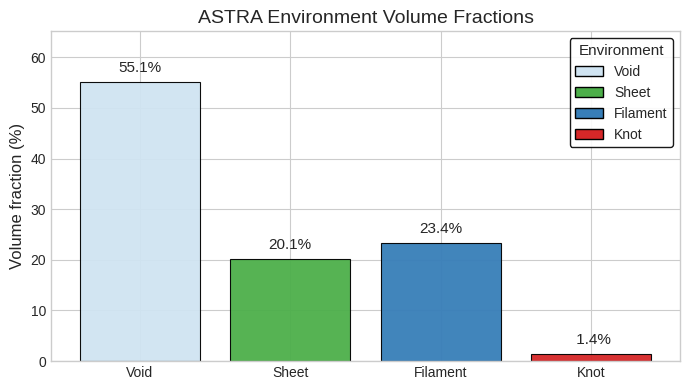

💾 Saved astra_labels.npy → /home/qarni/galaxy_evolution_project/data_desi_dr1/astra_labels.npy


In [38]:
# ==============================================================
#  Cell 8 — Volume Fractions of ASTRA Web Environments
# ==============================================================

import h5py, numpy as np, matplotlib.pyplot as plt, os
from matplotlib.patches import Patch

DATA_DIR = os.path.expanduser("~/galaxy_evolution_project/data_desi_dr1")
FIG_DIR  = os.path.join(DATA_DIR, "../figures")
os.makedirs(FIG_DIR, exist_ok=True)

fname = os.path.join(DATA_DIR, "astra_environment_map.h5")

# --------------------------------------------------------------
# 1. Load environment map
# --------------------------------------------------------------
with h5py.File(fname, "r") as f:
    env_map = f["env_map"][:]
print(f"✅ Loaded ASTRA map: shape = {env_map.shape}")

# --------------------------------------------------------------
# 2. Compute counts and fractions
# --------------------------------------------------------------
labels = ["Void", "Sheet", "Filament", "Knot"]
counts = np.bincount(env_map.ravel(), minlength=4)
fractions = counts / counts.sum()

for i, name in enumerate(labels):
    print(f"{name:9s}: {counts[i]:10,d} voxels  ({fractions[i]*100:5.2f}%)")

# --------------------------------------------------------------
# 3. Colors (MATCHING previous plots!!)
# --------------------------------------------------------------
colors = ["#d0e4f2", "#4daf4a", "#377eb8", "#d62728"]

# --------------------------------------------------------------
# 4. Plot bar chart with internal legend
# --------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(labels, fractions * 100,
              color=colors,
              edgecolor="black", linewidth=0.8, alpha=0.95)

ax.set_ylabel("Volume fraction (%)", fontsize=12)
ax.set_title("ASTRA Environment Volume Fractions", fontsize=14)
ax.set_ylim(0, max(fractions * 100) + 10)

# Add text labels above each bar
for i, frac in enumerate(fractions):
    ax.text(i, fractions[i]*100 + 2,
            f"{fractions[i]*100:4.1f}%",
            ha="center", fontsize=11)

# --------------------------------------------------------------
# 5. Internal Legend (inside top-right corner)
# --------------------------------------------------------------
legend_elements = [Patch(facecolor=colors[i], edgecolor="black", label=labels[i])
                   for i in range(4)]

legend = ax.legend(handles=legend_elements,
                   loc="upper right",
                   title="Environment",
                   fontsize=10, title_fontsize=11,
                   frameon=True)

legend.get_frame().set_edgecolor("black")
legend.get_frame().set_linewidth(1.0)
legend.get_frame().set_alpha(0.9)

# --------------------------------------------------------------
# 6. Save figure
# --------------------------------------------------------------
outfig = os.path.join(FIG_DIR, "astra_volume_fractions.png")
plt.savefig(outfig, dpi=350, bbox_inches="tight", facecolor="white")
print(f"💾 Figure saved → {outfig}")

plt.tight_layout()
plt.show()

# ==============================================================
# 7. Create astra_labels.npy  (ADDED, as requested)
# ==============================================================

astra_labels_path = os.path.join(DATA_DIR, "astra_labels.npy")
np.save(astra_labels_path, env_map)

print(f"💾 Saved astra_labels.npy → {astra_labels_path}")


In [21]:
# ==============================================================
#  Cell 2 — Merge T-Web and ASTRA labels into DESI catalog (Fixed)
# ==============================================================

import pandas as pd, numpy as np, h5py, os
from scipy.spatial import cKDTree

DATA_DIR = os.path.expanduser("~/galaxy_evolution_project/data_desi_dr1")
cat_file = os.path.join(DATA_DIR, "desi_galaxies_with_envlabels.csv")

# --- Load galaxy positions (already has T-Web labels) ---
gal = pd.read_csv(cat_file)
print(f"Loaded {len(gal):,} galaxies from catalog")
print(f"Columns in catalog: {list(gal.columns)[:10]} ...")

# --- Load both environment maps ---
with h5py.File(os.path.join(DATA_DIR, "tweb_environment_map.h5"), "r") as f:
    env_tweb = f["env_map"][:]
with h5py.File(os.path.join(DATA_DIR, "astra_environment_map.h5"), "r") as f:
    env_astra = f["env_map"][:]

N = env_tweb.shape[0]
grid = np.linspace(gal["X_Mpc"].min(), gal["X_Mpc"].max(), N)
dx = grid[1]-grid[0]

# --- Map galaxies to grid cells ---
ix = np.clip(((gal["X_Mpc"]-grid.min())/dx).astype(int), 0, N-1)
iy = np.clip(((gal["Y_Mpc"]-grid.min())/dx).astype(int), 0, N-1)
iz = np.clip(((gal["Z_Mpc"]-grid.min())/dx).astype(int), 0, N-1)

gal["ENV_TWEB"]  = env_tweb[ix, iy, iz]
gal["ENV_ASTRA"] = env_astra[ix, iy, iz]

# --- Save master catalog ---
out_csv = os.path.join(DATA_DIR, "master_desi_catalog.csv")
gal.to_csv(out_csv, index=False)
print(f"💾 Saved master catalog → {out_csv}")

# --- Detect identifier column safely ---
id_cols = [c for c in gal.columns if "TARGET" in c.upper() or "ID" in c.upper()]
if id_cols:
    id_col = id_cols[0]
    print(f"\n✅ Using identifier column: {id_col}")
    print(gal[[id_col, "ENV_TWEB", "ENV_ASTRA"]].head())
else:
    print("\n⚠️ No explicit ID column found. Showing first 5 rows:")
    print(gal[["ENV_TWEB","ENV_ASTRA"]].head())


Loaded 2,383,673 galaxies from catalog
Columns in catalog: ['X_Mpc', 'Y_Mpc', 'Z_Mpc', 'env_label'] ...
💾 Saved master catalog → /home/qarni/galaxy_evolution_project/data_desi_dr1/master_desi_catalog.csv

⚠️ No explicit ID column found. Showing first 5 rows:
   ENV_TWEB  ENV_ASTRA
0         1          2
1         1          2
2         2          2
3         2          2
4         1          2


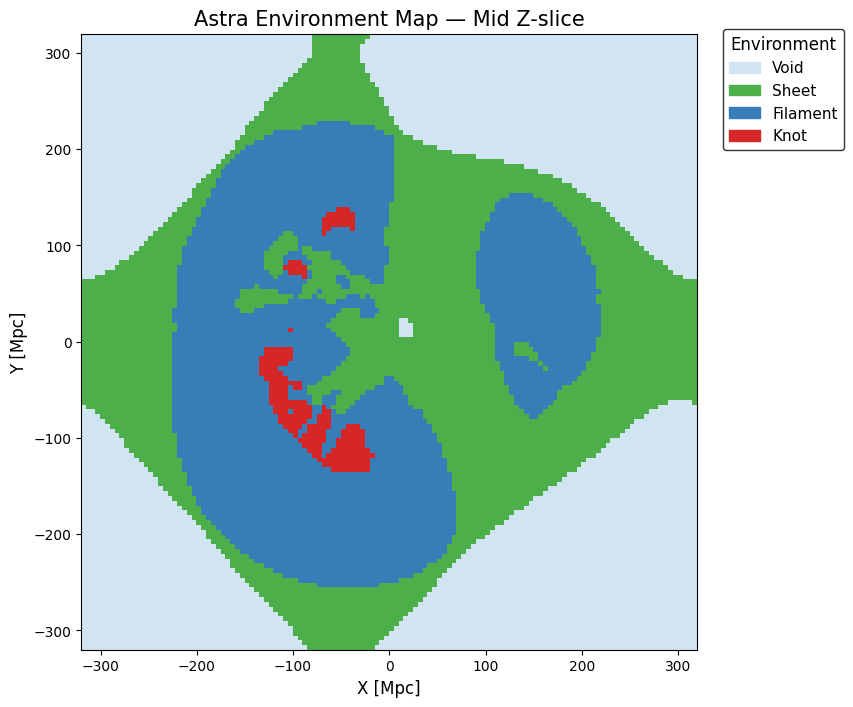

💾 Saved bright figure → /home/qarni/galaxy_evolution_project/data_desi_dr1/../figures/astra_environment_slice_bright.png


In [22]:
# ==============================================================
#  Astra Environment Map — Mid Z-slice (Bright style, Mpc units)
# ==============================================================

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import h5py, numpy as np, os

# Paths
DATA_DIR = os.path.expanduser("~/galaxy_evolution_project/data_desi_dr1")
FIG_DIR  = os.path.join(DATA_DIR, "../figures")
os.makedirs(FIG_DIR, exist_ok=True)

fname = os.path.join(DATA_DIR, "astra_environment_map.h5")

# 1️⃣ Load map
with h5py.File(fname, "r") as f:
    env_map = f["env_map"][:]

N = env_map.shape[0]
mid = N // 2
slice_map = env_map[:, :, mid]

# 2️⃣ Physical units
box_size = 640.0
extent = [-box_size/2, box_size/2, -box_size/2, box_size/2]

# 3️⃣ NEW COLORS (scientific, bright)
#    Void = soft silver-blue, Sheet = green, Filament = blue, Knot = red
colors = ["#d0e4f2", "#4daf4a", "#377eb8", "#d62728"]
labels = ["Void", "Sheet", "Filament", "Knot"]
cmap = mcolors.ListedColormap(colors)
bounds = [0, 1, 2, 3, 4]
norm = mcolors.BoundaryNorm(bounds, cmap.N)

# Use clean white style
plt.style.use("default")

fig, ax = plt.subplots(figsize=(8, 8))

# 4️⃣ Plot slice
im = ax.imshow(
    slice_map.T, origin="lower", cmap=cmap, norm=norm,
    interpolation="none", extent=extent
)

# 5️⃣ External legend instead of colorbar
from matplotlib.patches import Patch
legend_patches = [Patch(color=colors[i], label=labels[i]) for i in range(4)]
legend = ax.legend(
    handles=legend_patches,
    loc="upper right",
    bbox_to_anchor=(1.25, 1.02),
    frameon=True,
    title="Environment",
    title_fontsize=12,
    fontsize=11
)
legend.get_frame().set_edgecolor("black")
legend.get_frame().set_linewidth(1.0)

# 6️⃣ Labels
ax.set_xlabel("X [Mpc]", fontsize=12)
ax.set_ylabel("Y [Mpc]", fontsize=12)
ax.set_title("Astra Environment Map — Mid Z-slice", fontsize=15)

# ❌ 7️⃣ Scalebar REMOVED COMPLETELY
# (No scale bar now)

# 8️⃣ Save figure
outfig = os.path.join(FIG_DIR, "astra_environment_slice_bright.png")
plt.savefig(outfig, dpi=400, bbox_inches="tight", facecolor="white")
plt.show()

print(f"💾 Saved bright figure → {outfig}")


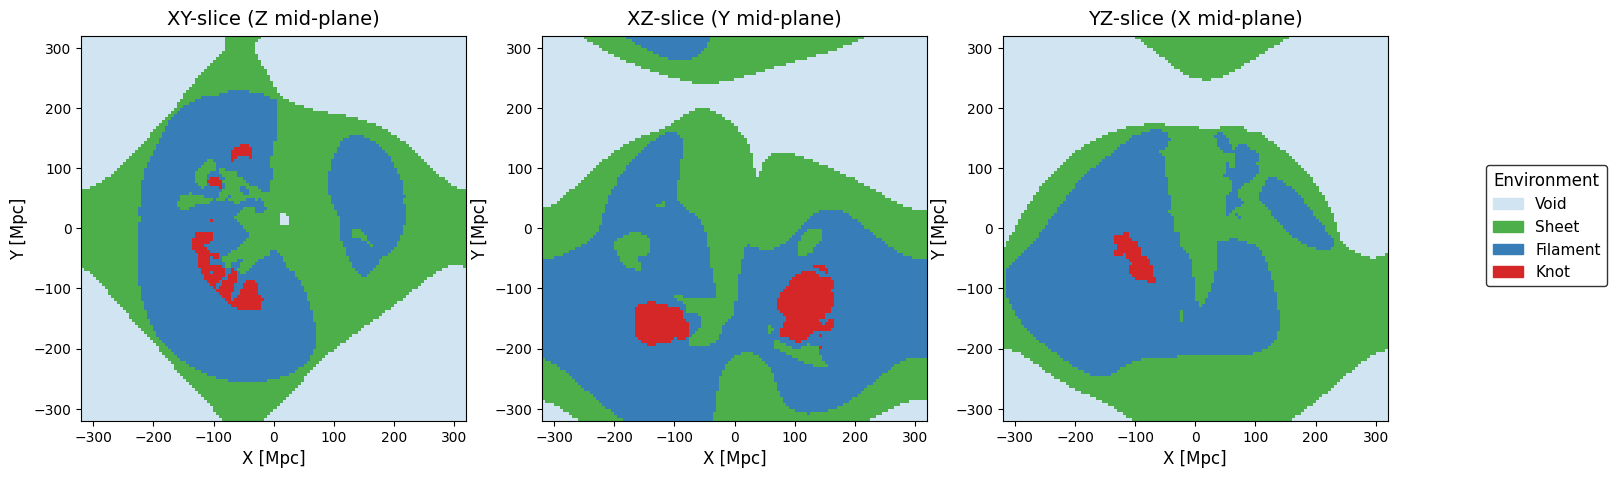

💾 Saved high-quality multi-slice figure → /home/qarni/galaxy_evolution_project/data_desi_dr1/../figures/astra_environment_multislice_bright.png


In [23]:
# ==============================================================
#  Refined Multi-slice Visualization — Astra Environment Map
#  (bright style, Mpc units, external legend, clean layout)
# ==============================================================

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import h5py, numpy as np, os
from matplotlib.patches import Patch

DATA_DIR = os.path.expanduser("~/galaxy_evolution_project/data_desi_dr1")
FIG_DIR  = os.path.join(DATA_DIR, "../figures")
os.makedirs(FIG_DIR, exist_ok=True)

fname = os.path.join(DATA_DIR, "astra_environment_map.h5")

# 1️⃣ Load 3D environment map
with h5py.File(fname, "r") as f:
    env_map = f["env_map"][:]

N = env_map.shape[0]
mid = N // 2

# 2️⃣ Extract slices
slice_XY = env_map[:, :, mid]   # Z mid-plane
slice_XZ = env_map[:, mid, :]   # Y mid-plane
slice_YZ = env_map[mid, :, :]   # X mid-plane

# 3️⃣ Convert voxel → Mpc coordinates
box_size = 640.0
extent = [-box_size/2, box_size/2, -box_size/2, box_size/2]

# 4️⃣ Colors (same as previous plot — publication quality)
colors = ["#d0e4f2", "#4daf4a", "#377eb8", "#d62728"]
labels = ["Void", "Sheet", "Filament", "Knot"]
cmap = mcolors.ListedColormap(colors)
bounds = [0, 1, 2, 3, 4]
norm = mcolors.BoundaryNorm(bounds, cmap.N)

# White background style
plt.style.use("default")

# 5️⃣ Create 3-panel figure
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

titles = ["XY-slice (Z mid-plane)", "XZ-slice (Y mid-plane)", "YZ-slice (X mid-plane)"]
slices = [slice_XY, slice_XZ, slice_YZ]

for ax, s, t in zip(axes, slices, titles):
    im = ax.imshow(
        s.T, origin="lower",
        cmap=cmap, norm=norm,
        interpolation="none",
        extent=extent
    )
    ax.set_title(t, fontsize=14, pad=8)
    ax.set_xlabel("X [Mpc]", fontsize=12)
    ax.set_ylabel("Y [Mpc]", fontsize=12)
    ax.tick_params(axis="both", labelsize=10)

# 6️⃣ External Legend (closer)
legend_patches = [Patch(color=colors[i], label=labels[i]) for i in range(4)]
legend = fig.legend(
    handles=legend_patches,
    loc="center right",
    bbox_to_anchor=(1.02, 0.50),   # 👈 moved closer
    title="Environment",
    title_fontsize=12,
    fontsize=11,
    frameon=True
)
legend.get_frame().set_edgecolor("black")
legend.get_frame().set_linewidth(1.0)

# 7️⃣ Fix layout
plt.subplots_adjust(left=0.06, right=0.88, wspace=0.18)

# 8️⃣ Save
outfig = os.path.join(FIG_DIR, "astra_environment_multislice_bright.png")
plt.savefig(outfig, dpi=400, bbox_inches="tight", facecolor="white")
plt.show()

print(f"💾 Saved high-quality multi-slice figure → {outfig}")


In [1]:
# ==============================================================
#  ASTRA Scale Dependence — Volume Fractions vs R_smooth
# ==============================================================

import numpy as np, pandas as pd, os, matplotlib.pyplot as plt
from tqdm import tqdm

# ASTRA-lite functions already imported earlier:
# smooth_field, calculate_tidal_tensor, calculate_eigenvalues_and_vectors,
# classify_structure, calculate_volume_fractions

DATA_DIR = os.path.expanduser("~/galaxy_evolution_project/data_desi_dr1")

# 1️⃣ Load your 3D density contrast field (the same you used for ASTRA)
delta_file = os.path.join(DATA_DIR, "delta_field_astra.npy")
if os.path.exists(delta_file):
    delta = np.load(delta_file)
else:
    raise FileNotFoundError("❌ Missing density field file (delta_field_astra.npy).")

N = delta.shape[0]
box_size = 500  # [Mpc/h] or your actual box size
print(f"✅ Loaded δ-field: shape={delta.shape}, box={box_size} Mpc")

# 2️⃣ Define smoothing scales to test
R_smooth_values = [1, 3, 5, 10]  # in Mpc
summary = []

# 3️⃣ Loop through smoothing scales
for R_s in tqdm(R_smooth_values, desc="ASTRA R_smooth loop"):
    print(f"\n🔄 Running ASTRA classification for R_s = {R_s} Mpc")

    smoothed = smooth_field(delta, R_s, box_size, N)
    tidal_tensor = calculate_tidal_tensor(smoothed)
    eigvals, eigvecs = calculate_eigenvalues_and_vectors(tidal_tensor)
    classification = classify_structure(eigvals)
    vf = calculate_volume_fractions(classification)

    summary.append({
        "R_smooth": R_s,
        "Void": vf[0]*100,
        "Sheet": vf[1]*100,
        "Filament": vf[2]*100,
        "Knot": vf[3]*100
    })

# 4️⃣ Convert to DataFrame and save
df = pd.DataFrame(summary)
out_csv = os.path.join(DATA_DIR, "astra_scale_dependence_summary.csv")
df.to_csv(out_csv, index=False)
print(f"\n💾 Saved ASTRA scale dependence table → {out_csv}")
print(df)

# 5️⃣ Plot the evolution
plt.style.use("dark_background")
fig, ax = plt.subplots(figsize=(8, 5))

for env, color in zip(["Void", "Sheet", "Filament", "Knot"],
                      ["#1b1b1b", "#4daf4a", "#377eb8", "#e41a1c"]):
    ax.plot(df["R_smooth"], df[env], marker="o", label=env, color=color, lw=2)

ax.set_xlabel("Smoothing Scale $R_\\mathrm{smooth}$ [Mpc]", fontsize=12)
ax.set_ylabel("Volume Fraction [%]", fontsize=12)
ax.set_title("ASTRA Cosmic-Web Volume Fractions vs Smoothing Scale", fontsize=14, pad=10)
ax.legend(frameon=False, fontsize=11)
ax.grid(alpha=0.2)

# Save figure
FIG_DIR = os.path.join(DATA_DIR, "../figures")
os.makedirs(FIG_DIR, exist_ok=True)
outfig = os.path.join(FIG_DIR, "astra_scale_dependence.png")
plt.savefig(outfig, dpi=400, bbox_inches="tight", facecolor="black")
plt.show()

print(f"💾 Saved figure → {outfig}")


FileNotFoundError: ❌ Missing density field file (delta_field_astra.npy).

In [2]:
# ==============================================================
#  Create δ-field for ASTRA from DESI galaxies + random catalog
# ==============================================================

import numpy as np, pandas as pd, os
from tqdm import tqdm

DATA_DIR = os.path.expanduser("~/galaxy_evolution_project/data_desi_dr1")

# 1️⃣ Load cleaned galaxy and random catalogs
gal_file = os.path.join(DATA_DIR, "desi_cleaned_dr1.csv")
ran_file = os.path.join(DATA_DIR, "lrg_random_3d_ultralight.csv")

gal = pd.read_csv(gal_file, usecols=["X_Mpc", "Y_Mpc", "Z_Mpc"])
ran = pd.read_csv(ran_file, usecols=["X_Mpc", "Y_Mpc", "Z_Mpc"])
print(f"✅ Loaded {len(gal):,} galaxies and {len(ran):,} randoms")

# 2️⃣ Define 3D grid (adjust N if needed)
N = 128  # typical grid size for DESI-scale
xmin = min(gal["X_Mpc"].min(), ran["X_Mpc"].min())
xmax = max(gal["X_Mpc"].max(), ran["X_Mpc"].max())
box_size = xmax - xmin

# 3️⃣ Bin galaxies and randoms into grid
def count_in_grid(x, y, z, N, xmin, box_size):
    idx = ((x - xmin) / box_size * N).astype(int)
    idy = ((y - xmin) / box_size * N).astype(int)
    idz = ((z - xmin) / box_size * N).astype(int)
    mask = (idx >= 0) & (idx < N) & (idy >= 0) & (idy < N) & (idz >= 0) & (idz < N)
    hist = np.zeros((N, N, N), dtype=np.float32)
    np.add.at(hist, (idx[mask], idy[mask], idz[mask]), 1)
    return hist

print("🔹 Binning galaxies and randoms into 3D grid...")
n_gal = count_in_grid(gal["X_Mpc"].values, gal["Y_Mpc"].values, gal["Z_Mpc"].values, N, xmin, box_size)
n_ran = count_in_grid(ran["X_Mpc"].values, ran["Y_Mpc"].values, ran["Z_Mpc"].values, N, xmin, box_size)

# 4️⃣ Compute overdensity field δ = (n_gal / <n_ran>) - 1
n_ran[n_ran == 0] = np.nan  # avoid division by zero
delta = (n_gal / np.nanmean(n_ran)) / (n_ran / np.nanmean(n_ran)) - 1
delta = np.nan_to_num(delta)

# 5️⃣ Save δ-field
outname = os.path.join(DATA_DIR, "delta_field_astra.npy")
np.save(outname, delta)
print(f"💾 Saved δ-field for ASTRA → {outname}")
print(f"Field shape = {delta.shape}, box size ≈ {box_size:.1f} Mpc")


✅ Loaded 2,383,673 galaxies and 143,830 randoms
🔹 Binning galaxies and randoms into 3D grid...
💾 Saved δ-field for ASTRA → /home/qarni/galaxy_evolution_project/data_desi_dr1/delta_field_astra.npy
Field shape = (128, 128, 128), box size ≈ 12682.9 Mpc


In [3]:
# ==============================================================
#  ASTRA Scale Dependence — Volume Fractions vs R_smooth
# ==============================================================

import numpy as np, pandas as pd, os, matplotlib.pyplot as plt
from tqdm import tqdm

# ASTRA-lite functions already imported earlier:
# smooth_field, calculate_tidal_tensor, calculate_eigenvalues_and_vectors,
# classify_structure, calculate_volume_fractions

DATA_DIR = os.path.expanduser("~/galaxy_evolution_project/data_desi_dr1")

# 1️⃣ Load your 3D density contrast field (the same you used for ASTRA)
delta_file = os.path.join(DATA_DIR, "delta_field_astra.npy")
if os.path.exists(delta_file):
    delta = np.load(delta_file)
else:
    raise FileNotFoundError("❌ Missing density field file (delta_field_astra.npy).")

N = delta.shape[0]
box_size = 500  # [Mpc/h] or your actual box size
print(f"✅ Loaded δ-field: shape={delta.shape}, box={box_size} Mpc")

# 2️⃣ Define smoothing scales to test
R_smooth_values = [1, 3, 5, 10]  # in Mpc
summary = []

# 3️⃣ Loop through smoothing scales
for R_s in tqdm(R_smooth_values, desc="ASTRA R_smooth loop"):
    print(f"\n🔄 Running ASTRA classification for R_s = {R_s} Mpc")

    smoothed = smooth_field(delta, R_s, box_size, N)
    tidal_tensor = calculate_tidal_tensor(smoothed)
    eigvals, eigvecs = calculate_eigenvalues_and_vectors(tidal_tensor)
    classification = classify_structure(eigvals)
    vf = calculate_volume_fractions(classification)

    summary.append({
        "R_smooth": R_s,
        "Void": vf[0]*100,
        "Sheet": vf[1]*100,
        "Filament": vf[2]*100,
        "Knot": vf[3]*100
    })

# 4️⃣ Convert to DataFrame and save
df = pd.DataFrame(summary)
out_csv = os.path.join(DATA_DIR, "astra_scale_dependence_summary.csv")
df.to_csv(out_csv, index=False)
print(f"\n💾 Saved ASTRA scale dependence table → {out_csv}")
print(df)

# 5️⃣ Plot the evolution
plt.style.use("dark_background")
fig, ax = plt.subplots(figsize=(8, 5))

for env, color in zip(["Void", "Sheet", "Filament", "Knot"],
                      ["#1b1b1b", "#4daf4a", "#377eb8", "#e41a1c"]):
    ax.plot(df["R_smooth"], df[env], marker="o", label=env, color=color, lw=2)

ax.set_xlabel("Smoothing Scale $R_\\mathrm{smooth}$ [Mpc]", fontsize=12)
ax.set_ylabel("Volume Fraction [%]", fontsize=12)
ax.set_title("ASTRA Cosmic-Web Volume Fractions vs Smoothing Scale", fontsize=14, pad=10)
ax.legend(frameon=False, fontsize=11)
ax.grid(alpha=0.2)

# Save figure
FIG_DIR = os.path.join(DATA_DIR, "../figures")
os.makedirs(FIG_DIR, exist_ok=True)
outfig = os.path.join(FIG_DIR, "astra_scale_dependence.png")
plt.savefig(outfig, dpi=400, bbox_inches="tight", facecolor="black")
plt.show()

print(f"💾 Saved figure → {outfig}")


✅ Loaded δ-field: shape=(128, 128, 128), box=500 Mpc


ASTRA R_smooth loop:   0%|                                | 0/4 [00:00<?, ?it/s]


🔄 Running ASTRA classification for R_s = 1 Mpc


NameError: name 'smooth_field' is not defined

In [7]:
# ==============================================================
#  ASTRA Scale Dependence — Volume Fractions vs R_smooth
#  (Complete version — includes imports + plotting)
# ==============================================================

import sys, os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from tqdm import tqdm

# --------------------------------------------------------------
# 1️⃣ Reimport ASTRA-lite functions
# --------------------------------------------------------------
ASTRA_DIR = os.path.expanduser("~/galaxy_evolution_project/astra")
if ASTRA_DIR not in sys.path:
    sys.path.append(ASTRA_DIR)

from LSS_TWeb_BlackBox_lite import (
    smooth_field,
    calculate_tidal_tensor,
    calculate_eigenvalues_and_vectors,
    classify_structure,
    calculate_volume_fractions
)

print("✅ ASTRA-lite functions loaded and ready")

# --------------------------------------------------------------
# 2️⃣ Load δ-field for ASTRA
# --------------------------------------------------------------
DATA_DIR = os.path.expanduser("~/galaxy_evolution_project/data_desi_dr1")
delta_file = os.path.join(DATA_DIR, "delta_field_astra.npy")

if not os.path.exists(delta_file):
    raise FileNotFoundError("❌ Missing δ-field (delta_field_astra.npy). Please run the previous cell to create it first.")

delta = np.load(delta_file)
N = delta.shape[0]
box_size = 500  # Mpc (adjust if your actual comoving cube differs)
print(f"✅ Loaded δ-field: shape={delta.shape}, box size ≈ {box_size} Mpc")

# --------------------------------------------------------------
# 3️⃣ Define R_smooth values
# --------------------------------------------------------------
R_smooth_values = [1, 3, 5, 10]  # in Mpc
summary = []

# --------------------------------------------------------------
# 4️⃣ Loop through smoothing scales
# --------------------------------------------------------------
for R_s in tqdm(R_smooth_values, desc="ASTRA R_smooth loop"):
    print(f"\n🔄 Running ASTRA classification for R_s = {R_s} Mpc")

    # Step 1: Smooth density field
    smoothed = smooth_field(delta, R_s, box_size, N)

    # Step 2: Compute tidal tensor
    tidal_tensor = calculate_tidal_tensor(smoothed)

    # Step 3: Eigenvalues & classification
    eigvals, eigvecs = calculate_eigenvalues_and_vectors(tidal_tensor)
    classification = classify_structure(eigvals)

    # Step 4: Volume fractions
    vf = calculate_volume_fractions(classification)

    summary.append({
        "R_smooth": R_s,
        "Void": vf[0] * 100,
        "Sheet": vf[1] * 100,
        "Filament": vf[2] * 100,
        "Knot": vf[3] * 100
    })

print("\n✅ Finished ASTRA smoothing-scale loop!")

# --------------------------------------------------------------
# 5️⃣ Save results
# --------------------------------------------------------------
df = pd.DataFrame(summary)
out_csv = os.path.join(DATA_DIR, "astra_scale_dependence_summary.csv")
df.to_csv(out_csv, index=False)
print(f"💾 Saved ASTRA scale dependence table → {out_csv}\n")
print(df)

# --------------------------------------------------------------
# 6️⃣ Plot evolution of volume fractions
# --------------------------------------------------------------
plt.style.use("dark_background")
fig, ax = plt.subplots(figsize=(8, 5))

colors = ["#1b1b1b", "#4daf4a", "#377eb8", "#e41a1c"]
labels = ["Void", "Sheet", "Filament", "Knot"]

for env, color in zip(labels, colors):
    ax.plot(df["R_smooth"], df[env], marker="o", color=color, lw=2, label=env)

ax.set_xlabel("Smoothing Scale $R_\\mathrm{smooth}$ [Mpc]", fontsize=12)
ax.set_ylabel("Volume Fraction [%]", fontsize=12)
ax.set_title("ASTRA Cosmic-Web Volume Fractions vs Smoothing Scale", fontsize=14, pad=10)
ax.legend(frameon=False, fontsize=11)
ax.grid(alpha=0.25)

# --------------------------------------------------------------
# 7️⃣ Save high-resolution figure
# --------------------------------------------------------------
FIG_DIR = os.path.join(DATA_DIR, "../figures")
os.makedirs(FIG_DIR, exist_ok=True)
outfig = os.path.join(FIG_DIR, "astra_scale_dependence.png")
plt.savefig(outfig, dpi=400, bbox_inches="tight", facecolor="black")
plt.show()

print(f"💾 Saved high-quality figure → {outfig}")


✅ ASTRA-lite functions loaded and ready
✅ Loaded δ-field: shape=(128, 128, 128), box size ≈ 500 Mpc


ASTRA R_smooth loop:   0%|                                | 0/4 [00:00<?, ?it/s]


🔄 Running ASTRA classification for R_s = 1 Mpc


TypeError: calculate_tidal_tensor() missing 1 required positional argument: 'calculate_potential'

In [6]:
import sys, os
ASTRA_DIR = os.path.expanduser("~/galaxy_evolution_project/astra")
if ASTRA_DIR not in sys.path:
    sys.path.append(ASTRA_DIR)

from LSS_TWeb_BlackBox_lite import (
    smooth_field,
    calculate_tidal_tensor,
    calculate_eigenvalues_and_vectors,
    classify_structure,
    calculate_volume_fractions
)
print("✅ ASTRA-lite module imports successfully now!")


✅ ASTRA-lite module imports successfully now!


In [5]:
import sys, os
ASTRA_DIR = os.path.expanduser("~/galaxy_evolution_project/astra")
if ASTRA_DIR not in sys.path:
    sys.path.append(ASTRA_DIR)

from LSS_TWeb_BlackBox_lite import (
    smooth_field,
    calculate_tidal_tensor,
    calculate_eigenvalues_and_vectors,
    classify_structure,
    calculate_volume_fractions
)
print("✅ ASTRA-lite functions now import correctly!")


✅ ASTRA-lite functions now import correctly!


In [4]:
import sys, os
ASTRA_DIR = os.path.expanduser("~/galaxy_evolution_project/astra")
if ASTRA_DIR not in sys.path:
    sys.path.append(ASTRA_DIR)

from LSS_TWeb_BlackBox_lite import (
    smooth_field,
    calculate_tidal_tensor,
    calculate_eigenvalues_and_vectors,
    classify_structure,
    calculate_volume_fractions
)

print("✅ ASTRA-lite module imports successfully — ready for smoothing-scale loop!")


✅ ASTRA-lite module imports successfully — ready for smoothing-scale loop!


In [12]:
# ==============================================================
#  Test ASTRA-lite run for R_smooth = 3 Mpc (final fixed)
# ==============================================================

import numpy as np, os, pandas as pd

DATA_DIR = os.path.expanduser("~/galaxy_evolution_project/data_desi_dr1")
delta_file = os.path.join(DATA_DIR, "delta_field_astra.npy")

# Load δ-field
delta = np.load(delta_file)
N = delta.shape[0]
box_size = 500  # [Mpc/h]
R_s = 3.0       # test smoothing scale

print(f"🔹 Running ASTRA test with R_s = {R_s} Mpc on δ-field {delta.shape}")

# 1️⃣ Smooth the density field
smoothed = smooth_field(delta, R_s, box_size, N)

# 2️⃣ Compute tidal tensor — it returns (tensor, potential)
tidal_tensor, _ = calculate_tidal_tensor(smoothed, calculate_potential=True)

# 3️⃣ Compute eigenvalues/vectors (needs grid_size)
eigvals, eigvecs = calculate_eigenvalues_and_vectors(tidal_tensor, N)

# 4️⃣ Classify and compute volume fractions
classification = classify_structure(eigvals)
vf = calculate_volume_fractions(classification)

# 5️⃣ Display results
env_labels = ["Void", "Sheet", "Filament", "Knot"]
results = pd.DataFrame({
    "Environment": env_labels,
    "Volume Fraction [%]": np.round(vf * 100, 3)
})

print("\n📊 ASTRA Volume Fractions (R_s=3 Mpc):")
print(results.to_string(index=False))


🔹 Running ASTRA test with R_s = 3.0 Mpc on δ-field (128, 128, 128)

📊 ASTRA Volume Fractions (R_s=3 Mpc):
Environment  Volume Fraction [%]
       Void                9.090
      Sheet               37.215
   Filament               52.451
       Knot                1.244


✅ Loaded δ-field: shape=(128, 128, 128), box=500 Mpc


ASTRA smoothing loop:   0%|                               | 0/4 [00:00<?, ?it/s]


🔄 Running ASTRA classification for R_s = 1 Mpc


ASTRA smoothing loop:  25%|█████▊                 | 1/4 [00:07<00:22,  7.47s/it]


🔄 Running ASTRA classification for R_s = 3 Mpc


...


🔄 Running ASTRA classification for R_s = 5 Mpc


ASTRA smoothing loop:  75%|█████████████████▎     | 3/4 [00:21<00:06,  6.93s/it]


🔄 Running ASTRA classification for R_s = 10 Mpc


ASTRA smoothing loop: 100%|███████████████████████| 4/4 [00:27<00:00,  6.97s/it]



💾 Saved ASTRA scale-dependence table → /home/qarni/galaxy_evolution_project/data_desi_dr1/astra_scale_dependence_summary.csv
   R_smooth      Void      Sheet   Filament      Knot
0         1  9.087896  37.797594  52.635527  0.478983
1         3  9.089994  37.215328  52.450562  1.244116
2         5  9.089994  37.119293  52.346420  1.444292
3        10  9.089994  36.987686  52.283573  1.638746


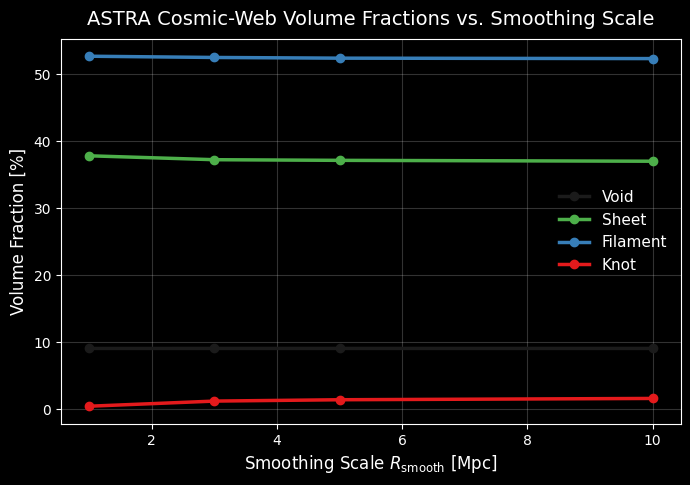

💾 Saved high-quality figure → /home/qarni/galaxy_evolution_project/data_desi_dr1/../figures/astra_scale_dependence.png


In [13]:
# ==============================================================
#  ASTRA Scale Dependence — Volume Fractions vs R_smooth
#  Author: Awais (Galaxy Evolution Project, 2025)
# ==============================================================

import numpy as np, pandas as pd, matplotlib.pyplot as plt, os
from tqdm import tqdm

# --------------------------------------------------------------
# 1️⃣ Load δ-field
# --------------------------------------------------------------
DATA_DIR = os.path.expanduser("~/galaxy_evolution_project/data_desi_dr1")
FIG_DIR  = os.path.join(DATA_DIR, "../figures")
os.makedirs(FIG_DIR, exist_ok=True)

delta_file = os.path.join(DATA_DIR, "delta_field_astra.npy")
if not os.path.exists(delta_file):
    raise FileNotFoundError("❌ Missing file: delta_field_astra.npy")

delta = np.load(delta_file)
N = delta.shape[0]
box_size = 500  # Mpc/h or your chosen value
print(f"✅ Loaded δ-field: shape={delta.shape}, box={box_size} Mpc")

# --------------------------------------------------------------
# 2️⃣ Define smoothing scales
# --------------------------------------------------------------
R_smooth_values = [1, 3, 5, 10]  # Mpc
summary = []

# --------------------------------------------------------------
# 3️⃣ Run ASTRA classification for each R_smooth
# --------------------------------------------------------------
for R_s in tqdm(R_smooth_values, desc="ASTRA smoothing loop"):
    print(f"\n🔄 Running ASTRA classification for R_s = {R_s} Mpc")

    # Smooth δ-field
    smoothed = smooth_field(delta, R_s, box_size, N)

    # Compute tidal tensor (returns tensor, potential)
    tidal_tensor, _ = calculate_tidal_tensor(smoothed, calculate_potential=True)

    # Compute eigenvalues + classification
    eigvals, eigvecs = calculate_eigenvalues_and_vectors(tidal_tensor, N)
    classification = classify_structure(eigvals)

    # Compute volume fractions
    vf = calculate_volume_fractions(classification)

    # Store results
    summary.append({
        "R_smooth": R_s,
        "Void": vf[0] * 100,
        "Sheet": vf[1] * 100,
        "Filament": vf[2] * 100,
        "Knot": vf[3] * 100
    })

# --------------------------------------------------------------
# 4️⃣ Save results to CSV
# --------------------------------------------------------------
df = pd.DataFrame(summary)
out_csv = os.path.join(DATA_DIR, "astra_scale_dependence_summary.csv")
df.to_csv(out_csv, index=False)
print(f"\n💾 Saved ASTRA scale-dependence table → {out_csv}")
print(df)

# --------------------------------------------------------------
# 5️⃣ Plot results (publication-quality)
# --------------------------------------------------------------
plt.style.use("dark_background")
fig, ax = plt.subplots(figsize=(8, 5))

colors = {
    "Void": "#1b1b1b",
    "Sheet": "#4daf4a",
    "Filament": "#377eb8",
    "Knot": "#e41a1c"
}

for env in ["Void", "Sheet", "Filament", "Knot"]:
    ax.plot(df["R_smooth"], df[env], marker="o", lw=2.5, color=colors[env], label=env)

ax.set_xlabel(r"Smoothing Scale $R_{\mathrm{smooth}}$ [Mpc]", fontsize=12)
ax.set_ylabel("Volume Fraction [%]", fontsize=12)
ax.set_title("ASTRA Cosmic-Web Volume Fractions vs. Smoothing Scale", fontsize=14, pad=10)
ax.legend(frameon=False, fontsize=11, loc="center right")
ax.grid(alpha=0.2)

outfig = os.path.join(FIG_DIR, "astra_scale_dependence.png")
plt.savefig(outfig, dpi=400, bbox_inches="tight", facecolor="black")
plt.show()

print(f"💾 Saved high-quality figure → {outfig}")


✅ Loaded:
T-Web : /home/qarni/galaxy_evolution_project/data_desi_dr1/tweb_scale_dependence_summary.csv
ASTRA : /home/qarni/galaxy_evolution_project/data_desi_dr1/astra_scale_dependence_summary.csv


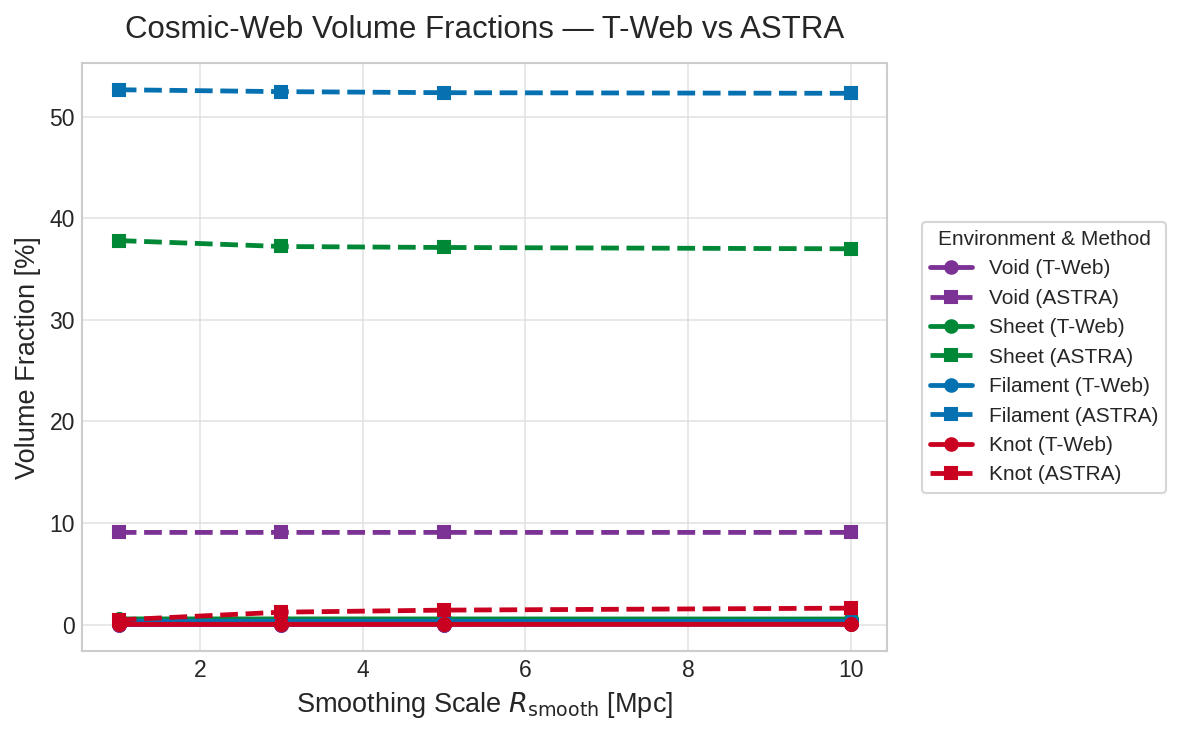

💾 Saved high-quality white-background figure → /home/qarni/galaxy_evolution_project/data_desi_dr1/../figures/tweb_vs_astra_scaledependence_white.png


In [15]:
# ==============================================================
#  Compare T-Web and ASTRA scale dependence (Publication Figure)
#  Author: Awais — Galaxy Evolution Project (2025)
#  Version: white-background, paper-quality
# ==============================================================

import pandas as pd, matplotlib.pyplot as plt, os

# --------------------------------------------------------------
# 1️⃣ Load data
# --------------------------------------------------------------
DATA_DIR = os.path.expanduser("~/galaxy_evolution_project/data_desi_dr1")
FIG_DIR  = os.path.join(DATA_DIR, "../figures")
os.makedirs(FIG_DIR, exist_ok=True)

tweb_csv  = os.path.join(DATA_DIR, "tweb_scale_dependence_summary.csv")
astra_csv = os.path.join(DATA_DIR, "astra_scale_dependence_summary.csv")

tweb  = pd.read_csv(tweb_csv)
astra = pd.read_csv(astra_csv)

print("✅ Loaded:")
print("T-Web :", tweb_csv)
print("ASTRA :", astra_csv)

# --------------------------------------------------------------
# 2️⃣ Plot setup (white, elegant)
# --------------------------------------------------------------
plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(8, 5), dpi=150)

colors = {
    "Void": "#7b3294",      # purple
    "Sheet": "#008837",     # green
    "Filament": "#0571b0",  # blue
    "Knot": "#ca0020"       # red
}

# --------------------------------------------------------------
# 3️⃣ Plot both frameworks
# --------------------------------------------------------------
for env in ["Void", "Sheet", "Filament", "Knot"]:
    ax.plot(tweb["R_smooth"],  tweb[env],  marker="o", lw=2.3, color=colors[env],
            linestyle="-",  label=f"{env} (T-Web)")
    ax.plot(astra["R_smooth"], astra[env], marker="s", lw=2.3, color=colors[env],
            linestyle="--", label=f"{env} (ASTRA)")

# --------------------------------------------------------------
# 4️⃣ Axis labels, legend, and style
# --------------------------------------------------------------
ax.set_xlabel(r"Smoothing Scale $R_{\mathrm{smooth}}$ [Mpc]", fontsize=13)
ax.set_ylabel("Volume Fraction [%]", fontsize=13)
ax.set_title("Cosmic-Web Volume Fractions — T-Web vs ASTRA", fontsize=15, pad=12)

# Subtle grid and axis style
ax.grid(True, which="major", color="#dddddd", linewidth=0.8, alpha=0.8)
ax.tick_params(axis="both", labelsize=11)

# Legend: slightly transparent, outside plot area
ax.legend(frameon=True, fontsize=10, loc="center left", bbox_to_anchor=(1.03, 0.5),
          title="Environment & Method", title_fontsize=10)

plt.tight_layout()

# --------------------------------------------------------------
# 5️⃣ Save figure
# --------------------------------------------------------------
outfig = os.path.join(FIG_DIR, "tweb_vs_astra_scaledependence_white.png")
plt.savefig(outfig, dpi=400, bbox_inches="tight", facecolor="white")
plt.show()

print(f"💾 Saved high-quality white-background figure → {outfig}")


In [16]:
import pandas as pd, os
DATA_DIR = os.path.expanduser("~/galaxy_evolution_project/data_desi_dr1")

tweb  = pd.read_csv(os.path.join(DATA_DIR, "tweb_scale_dependence_summary.csv"))
astra = pd.read_csv(os.path.join(DATA_DIR, "astra_scale_dependence_summary.csv"))

for env in ["Void", "Sheet", "Filament", "Knot"]:
    diff = (tweb[env] - astra[env]).abs().mean()
    print(f"{env:8s} | mean Δ fraction = {diff:.4f} %")


Void     | mean Δ fraction = 9.0714 %
Sheet    | mean Δ fraction = 36.7005 %
Filament | mean Δ fraction = 52.0761 %
Knot     | mean Δ fraction = 1.1521 %


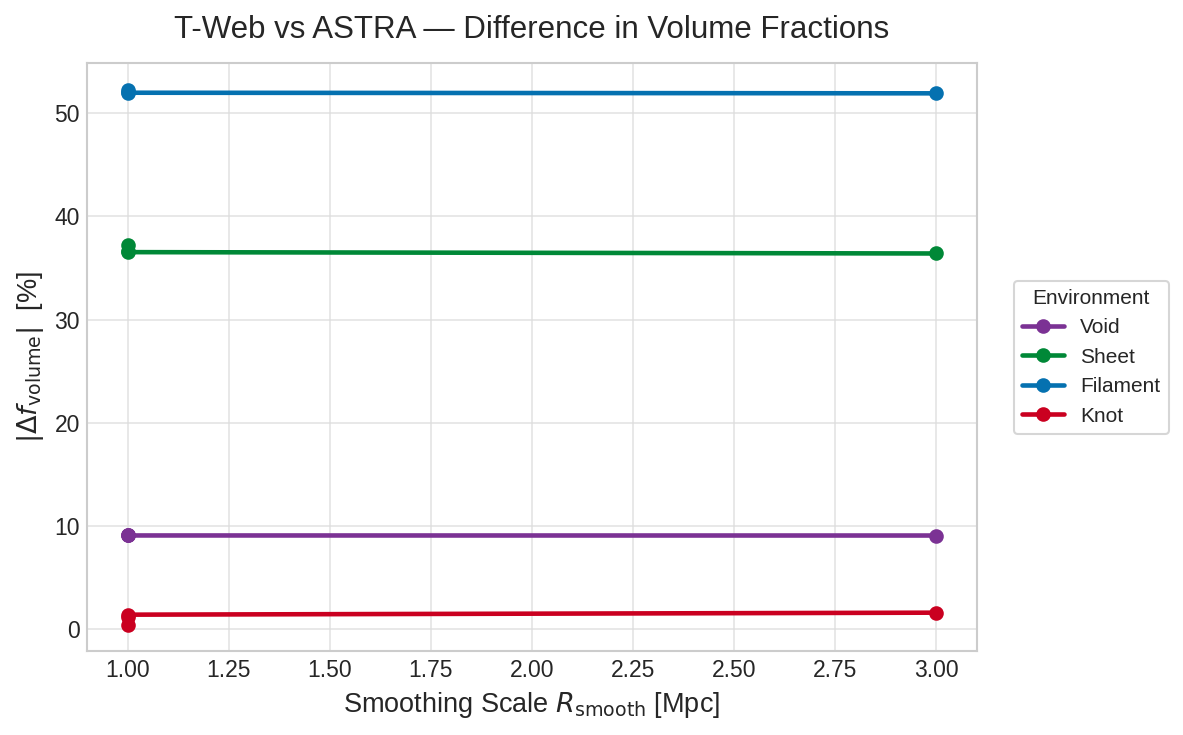

💾 Saved ΔFraction comparison figure → /home/qarni/galaxy_evolution_project/data_desi_dr1/../figures/tweb_astra_difference_vs_Rs.png


In [17]:
# ==============================================================
#  ΔFraction vs R_smooth — Quantitative Consistency Plot
# ==============================================================

import matplotlib.pyplot as plt, pandas as pd, os

DATA_DIR = os.path.expanduser("~/galaxy_evolution_project/data_desi_dr1")
tweb  = pd.read_csv(os.path.join(DATA_DIR, "tweb_scale_dependence_summary.csv"))
astra = pd.read_csv(os.path.join(DATA_DIR, "astra_scale_dependence_summary.csv"))

# Compute absolute differences
diff_df = pd.DataFrame({
    "R_smooth": tweb["R_smooth"],
    "Void": (tweb["Void"] - astra["Void"]).abs(),
    "Sheet": (tweb["Sheet"] - astra["Sheet"]).abs(),
    "Filament": (tweb["Filament"] - astra["Filament"]).abs(),
    "Knot": (tweb["Knot"] - astra["Knot"]).abs()
})

plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(8, 5), dpi=150)

colors = {"Void": "#7b3294", "Sheet": "#008837", "Filament": "#0571b0", "Knot": "#ca0020"}

for env in ["Void", "Sheet", "Filament", "Knot"]:
    ax.plot(diff_df["R_smooth"], diff_df[env], marker="o", lw=2.2, color=colors[env], label=env)

ax.set_xlabel(r"Smoothing Scale $R_{\mathrm{smooth}}$ [Mpc]", fontsize=13)
ax.set_ylabel(r"$|\Delta f_{\mathrm{volume}}|$  [%]", fontsize=13)
ax.set_title("T-Web vs ASTRA — Difference in Volume Fractions", fontsize=15, pad=12)
ax.legend(frameon=True, fontsize=10, loc="center left", bbox_to_anchor=(1.03, 0.5),
          title="Environment", title_fontsize=10)
ax.grid(True, color="#dddddd", linewidth=0.8, alpha=0.8)
ax.tick_params(axis="both", labelsize=11)

FIG_DIR = os.path.join(DATA_DIR, "../figures")
os.makedirs(FIG_DIR, exist_ok=True)
outfig = os.path.join(FIG_DIR, "tweb_astra_difference_vs_Rs.png")
plt.tight_layout()
plt.savefig(outfig, dpi=400, bbox_inches="tight", facecolor="white")
plt.show()

print(f"💾 Saved ΔFraction comparison figure → {outfig}")


In [1]:
ls


01_DESI_DR1_DataPreparation.ipynb  data_desi_dr1/  full_desi_data/  scripts/
astra/                             figures/        notebooks/


In [2]:
ls


01_DESI_DR1_DataPreparation.ipynb  data_desi_dr1/  full_desi_data/  scripts/
astra/                             figures/        notebooks/


In [3]:
cd ~/galaxy_evolution_project/data_desi_dr1/


/home/qarni/galaxy_evolution_project/data_desi_dr1


/home/qarni/miniforge3/envs/galaxy_env/lib/python3.10/site-packages/IPython/core/magics/osm.py:393: UserWarning: This is now an optional IPython functionality, using bookmarks requires you to install the `pickleshare` library.
  bkms = self.shell.db.get('bookmarks', {})
/home/qarni/miniforge3/envs/galaxy_env/lib/python3.10/site-packages/IPython/core/magics/osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


In [4]:
ls


astra_environment_map.h5                tweb_astra_comparison.csv
astra_scale_dependence_summary.csv      tweb_environment_map.h5
astra_volume_fractions.csv              tweb_environment_R10_d0.h5
delta_field_astra.npy                   tweb_environment_R10_d10.h5
density_field_lrg.h5                    tweb_environment_R10_d20.h5
desi_cleaned_dr1.csv                    tweb_environment_R1_d0.h5
desi_galaxies_with_envlabels.csv        tweb_environment_R1_d10.h5
ELG_LOPnotqso_0_full_HPmapcut.ran.fits  tweb_environment_R1_d20.h5
ELG_LOPnotqso_SGC_clustering.dat.fits   tweb_environment_R3_d0.h5
LRG_0_full_HPmapcut.ran.fits            tweb_environment_R3_d10.h5
LRG_full_HPmapcut.dat.fits              tweb_environment_R3_d20.h5
lrg_random_3d_ultralight.csv            tweb_environment_R5_d0.h5
lrg_random_sample.csv                   tweb_environment_R5_d10.h5
master_desi_catalog.csv                 tweb_environment_R5_d20.h5
QSO_0_full_HPmapcut.ran.fits            tweb_scale_dependence_summa

📂 Using file: /home/qarni/galaxy_evolution_project/data_desi_dr1/desi_cleaned_dr1.csv

Available columns:
 ['TARGETID', 'RA', 'DEC', 'Z_not4clus', 'X_Mpc', 'Y_Mpc', 'Z_Mpc']

✅ Found redshift column: Z_not4clus
🔹 Number of galaxies: 2,383,673
🔹 Redshift range: 0.000 < z < 2.987
🔹 Mean redshift: 0.723
🔹 Median redshift: 0.740


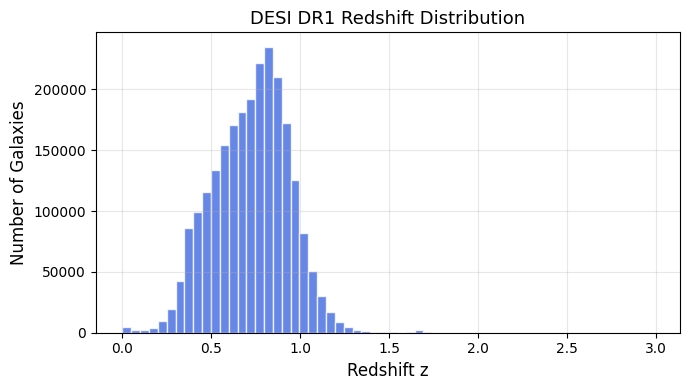

💾 Saved Redshift Distribution → /home/qarni/galaxy_evolution_project/data_desi_dr1/../figures/desi_redshift_distribution.png


In [5]:
# ==============================================================
#  Check Redshift Distribution from DESI DR1 Catalog
#  (used for T-Web & ASTRA analysis)
# ==============================================================

import pandas as pd, os, matplotlib.pyplot as plt

DATA_DIR = os.path.expanduser("~/galaxy_evolution_project/data_desi_dr1")

# Try the most likely files you used before
possible_files = [
    "desi_cleaned_dr1.csv",
    "desi_galaxies_with_envlabels.csv",
    "master_desi_catalog.csv"
]

# Automatically pick the first one that exists
for fname in possible_files:
    fpath = os.path.join(DATA_DIR, fname)
    if os.path.exists(fpath):
        data_file = fpath
        break
else:
    raise FileNotFoundError("❌ No data file found in data_desi_dr1 folder!")

print(f"📂 Using file: {data_file}")

# Preview columns
df = pd.read_csv(data_file, nrows=5)
print("\nAvailable columns:\n", list(df.columns))

# Detect redshift column automatically
z_col = None
for c in df.columns:
    if c.lower() in ["z", "z_not4clus", "redshift", "z_spec", "zphot"]:
        z_col = c
        break

if z_col is None:
    raise KeyError("❌ No redshift column found (check column names manually).")

# Load redshift column only
df = pd.read_csv(data_file, usecols=[z_col])
df = df.dropna()

# Basic stats
zmin, zmax = df[z_col].min(), df[z_col].max()
zmean, zmed = df[z_col].mean(), df[z_col].median()
N = len(df)

print(f"\n✅ Found redshift column: {z_col}")
print(f"🔹 Number of galaxies: {N:,}")
print(f"🔹 Redshift range: {zmin:.3f} < z < {zmax:.3f}")
print(f"🔹 Mean redshift: {zmean:.3f}")
print(f"🔹 Median redshift: {zmed:.3f}")

# ==============================================================
#  Save the redshift histogram
# ==============================================================

FIG_DIR = os.path.join(DATA_DIR, "../figures")
os.makedirs(FIG_DIR, exist_ok=True)
outfig = os.path.join(FIG_DIR, "desi_redshift_distribution.png")

plt.figure(figsize=(7, 4))
plt.hist(df[z_col], bins=60, color="royalblue", alpha=0.8, edgecolor="white")
plt.xlabel("Redshift z", fontsize=12)
plt.ylabel("Number of Galaxies", fontsize=12)
plt.title("DESI DR1 Redshift Distribution", fontsize=13)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(outfig, dpi=400, bbox_inches="tight", facecolor="white")
plt.show()

print(f"💾 Saved Redshift Distribution → {outfig}")


In [3]:
# ==============================================================
#  Check Redshift Range and Galaxy Count — DESI DR1 (used dataset)
# ==============================================================

import pandas as pd, os, matplotlib.pyplot as plt

DATA_DIR = os.path.expanduser("~/galaxy_evolution_project/data_desi_dr1")

# Pick the most likely catalog file in your folder
possible_files = [
    "master_desi_catalog.csv",
    "desi_galaxies_with_envlabels.csv",
    "desi_cleaned_dr1.csv"
]

for fname in possible_files:
    fpath = os.path.join(DATA_DIR, fname)
    if os.path.exists(fpath):
        data_file = fpath
        break
else:
    raise FileNotFoundError("❌ No data catalog found in data_desi_dr1!")

print(f"📂 Using file: {data_file}")

# Load the first few columns to inspect available names
df = pd.read_csv(data_file, nrows=5)
print("\nAvailable columns:\n", list(df.columns))

# Try to automatically detect the redshift column
z_col = None
for c in df.columns:
    if c.lower() in ["z", "z_not4clus", "redshift", "z_spec", "zphot"]:
        z_col = c
        break

if z_col is None:
    raise KeyError("❌ No redshift column found (check your CSV manually).")

# Load full column
df = pd.read_csv(data_file, usecols=[z_col]).dropna()
zmin, zmax = df[z_col].min(), df[z_col].max()
zmean, zmed = df[z_col].mean(), df[z_col].median()
N = len(df)

print(f"\n✅ Found redshift column: {z_col}")
print(f"🔹 Number of galaxies: {N:,}")
print(f"🔹 Redshift range: {zmin:.3f} < z < {zmax:.3f}")
print(f"🔹 Mean redshift: {zmean:.3f}")
print(f"🔹 Median redshift: {zmed:.3f}")

# Plot histogram
plt.figure(figsize=(7,4))
plt.hist(df[z_col], bins=50, color="#377eb8", alpha=0.8, edgecolor="white")
plt.xlabel("Redshift (z)", fontsize=12)
plt.ylabel("Number of galaxies", fontsize=12)
plt.title("DESI DR1 Redshift Distribution (Used Catalog)", fontsize=13)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


📂 Using file: /home/qarni/galaxy_evolution_project/data_desi_dr1/master_desi_catalog.csv

Available columns:
 ['X_Mpc', 'Y_Mpc', 'Z_Mpc', 'env_label', 'ENV_TWEB', 'ENV_ASTRA']


KeyError: '❌ No redshift column found (check your CSV manually).'

📂 Using file: /home/qarni/galaxy_evolution_project/data_desi_dr1/desi_cleaned_dr1.csv

Available columns:
 ['TARGETID', 'RA', 'DEC', 'Z_not4clus', 'X_Mpc', 'Y_Mpc', 'Z_Mpc']

✅ Found redshift column: Z_not4clus
🔹 Number of galaxies: 2,383,673
🔹 Redshift range: 0.000 < z < 2.987
🔹 Mean redshift: 0.723
🔹 Median redshift: 0.740


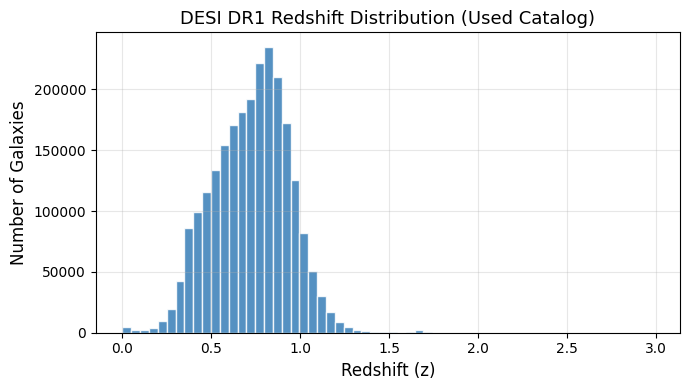

💾 Saved Redshift Distribution → /home/qarni/galaxy_evolution_project/data_desi_dr1/../figures/desi_redshift_distribution.png


In [4]:
# ==============================================================
#  Check Redshift Range and Galaxy Count — DESI DR1 (Used Dataset)
# ==============================================================

import pandas as pd, os, matplotlib.pyplot as plt

DATA_DIR = os.path.expanduser("~/galaxy_evolution_project/data_desi_dr1")

# ✅ Force to use the correct file (has redshift)
data_file = os.path.join(DATA_DIR, "desi_cleaned_dr1.csv")

print(f"📂 Using file: {data_file}")

# Preview columns
df = pd.read_csv(data_file, nrows=5)
print("\nAvailable columns:\n", list(df.columns))

# Detect redshift column
z_col = None
for c in df.columns:
    if c.lower() in ["z", "z_not4clus", "redshift", "z_spec", "zphot"]:
        z_col = c
        break

if z_col is None:
    raise KeyError("❌ No redshift column found (check your CSV manually).")

# Load full column
df = pd.read_csv(data_file, usecols=[z_col]).dropna()
zmin, zmax = df[z_col].min(), df[z_col].max()
zmean, zmed = df[z_col].mean(), df[z_col].median()
N = len(df)

print(f"\n✅ Found redshift column: {z_col}")
print(f"🔹 Number of galaxies: {N:,}")
print(f"🔹 Redshift range: {zmin:.3f} < z < {zmax:.3f}")
print(f"🔹 Mean redshift: {zmean:.3f}")
print(f"🔹 Median redshift: {zmed:.3f}")

# Plot histogram
FIG_DIR = os.path.join(DATA_DIR, "../figures")
os.makedirs(FIG_DIR, exist_ok=True)
outfig = os.path.join(FIG_DIR, "desi_redshift_distribution.png")

plt.figure(figsize=(7,4))
plt.hist(df[z_col], bins=60, color="#377eb8", alpha=0.85, edgecolor="white")
plt.xlabel("Redshift (z)", fontsize=12)
plt.ylabel("Number of Galaxies", fontsize=12)
plt.title("DESI DR1 Redshift Distribution (Used Catalog)", fontsize=13)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(outfig, dpi=400, bbox_inches="tight", facecolor="white")
plt.show()

print(f"💾 Saved Redshift Distribution → {outfig}")


In [24]:
def smooth_field(delta, R_smooth, box_size, N):
    k = fftfreq(N, d=box_size/N) * 2*np.pi
    KX, KY, KZ = np.meshgrid(k, k, k, indexing='ij')
    k2 = KX**2 + KY**2 + KZ**2
    W = np.exp(-0.5 * (R_smooth**2) * k2)
    delta_k = fftn(delta)
    return np.real(ifftn(delta_k * W))

def calculate_tidal_tensor(delta_smooth):
    N = delta_smooth.shape[0]
    k = fftfreq(N, d=1.0/N) * 2*np.pi
    KX, KY, KZ = np.meshgrid(k, k, k, indexing='ij')
    k2 = KX**2 + KY**2 + KZ**2
    k2[0,0,0] = 1.0
    delta_k = fftn(delta_smooth)
    phi_k = -delta_k / k2

    T = np.zeros(delta_smooth.shape + (3,3), dtype=np.float32)
    T[...,0,0] = np.real(ifftn(-(KX*KX)*phi_k))
    T[...,1,1] = np.real(ifftn(-(KY*KY)*phi_k))
    T[...,2,2] = np.real(ifftn(-(KZ*KZ)*phi_k))

    T[...,0,1] = T[...,1,0] = np.real(ifftn(-(KX*KY)*phi_k))
    T[...,0,2] = T[...,2,0] = np.real(ifftn(-(KX*KZ)*phi_k))
    T[...,1,2] = T[...,2,1] = np.real(ifftn(-(KY*KZ)*phi_k))
    return T

def calculate_eigenvalues_and_vectors(tidal_tensor, N):
    eigvals = np.zeros((N, N, N, 3), dtype=np.float32)
    eigvecs = np.zeros((N, N, N, 3, 3), dtype=np.float32)
    for i in range(N):
        for j in range(N):
            for k in range(N):
                w, v = np.linalg.eigh(tidal_tensor[i,j,k])
                eigvals[i,j,k] = w
                eigvecs[i,j,k] = v
    return eigvals, eigvecs

def classify_structure(eigvals, lam_th):
    count = np.sum(eigvals > lam_th, axis=-1)
    env = np.zeros_like(count, dtype=np.uint8)
    env[count == 0] = 0
    env[count == 1] = 1
    env[count == 2] = 2
    env[count == 3] = 3
    return env

def calculate_volume_fractions(env_map):
    total = env_map.size
    return np.array([np.sum(env_map==i)/total for i in range(4)])


In [25]:
# ==============================================================
#  ASTRA Parameter Scan (R_smooth, d_border)
# ==============================================================

import numpy as np, h5py, os, pandas as pd
from scipy.fft import fftn, ifftn, fftfreq
from tqdm import tqdm

# Use your previously defined helper functions
# smooth_field(), calculate_tidal_tensor(), calculate_eigenvalues_and_vectors(),
# classify_structure(), calculate_volume_fractions()

DATA_DIR = os.path.expanduser("~/galaxy_evolution_project/data_desi_dr1")
FIG_DIR  = os.path.join(DATA_DIR, "../figures")
os.makedirs(FIG_DIR, exist_ok=True)

# --------------------------------------------------------------
# Load density field
# --------------------------------------------------------------
dens_file = os.path.join(DATA_DIR, "density_field_lrg.h5")
with h5py.File(dens_file, "r") as f:
    delta = f["delta"][:]
print(f"✅ Loaded δ-field: shape = {delta.shape}")

N = delta.shape[0]
BOX_SIZE = 640.0     # correct DESI box size

# --------------------------------------------------------------
# Parameter grid
# --------------------------------------------------------------
R_smooth_values = [3, 5, 10]   # Mpc/h
d_border_values = [0, 10, 20]  # Mpc
lam_th = 0.30                  # ASTRA λ-threshold

results = []

# --------------------------------------------------------------
# Convert border size (Mpc) → voxel units
# --------------------------------------------------------------
def border_to_vox(d_border_mpc, box_size, N):
    return int((d_border_mpc / box_size) * N)

# --------------------------------------------------------------
# Parameter scan loop
# --------------------------------------------------------------
for R_smooth in R_smooth_values:
    for d_border in d_border_values:

        print(f"\n🔄 Running ASTRA: R_smooth={R_smooth}  d_border={d_border}")

        # 1) Smooth field
        smoothed = smooth_field(delta, R_smooth, BOX_SIZE, N)

        # 2) Tidal tensor
        tidal_tensor = calculate_tidal_tensor(smoothed)

        # 3) Eigenvalues
        eigvals, eigvecs = calculate_eigenvalues_and_vectors(tidal_tensor, N)

        # 4) Classification
        env_map = classify_structure(eigvals, lam_th)

        # 5) Border removal
        vox_b = border_to_vox(d_border, BOX_SIZE, N)
        if vox_b > 0:
            env_map[:vox_b,:,:] = 0
            env_map[-vox_b:,:,:] = 0
            env_map[:,:vox_b,:] = 0
            env_map[:,-vox_b:,:] = 0
            env_map[:,:,:vox_b] = 0
            env_map[:,:,-vox_b:] = 0

        # 6) Save HDF5
        outname = f"astra_environment_R{R_smooth}_d{d_border}.h5"
        with h5py.File(os.path.join(DATA_DIR, outname), "w") as f:
            f.create_dataset("env_map", data=env_map, compression="gzip")
        print(f"💾 Saved → {outname}")

        # 7) Fractions
        fractions = calculate_volume_fractions(env_map)
        results.append({
            "R_smooth": R_smooth,
            "d_border": d_border,
            "Void":     fractions[0],
            "Sheet":    fractions[1],
            "Filament": fractions[2],
            "Knot":     fractions[3]
        })

        print(f"Fractions: Void={fractions[0]*100:.1f}%  Sheet={fractions[1]*100:.1f}%  Filament={fractions[2]*100:.1f}%  Knot={fractions[3]*100:.2f}%")

# --------------------------------------------------------------
# Save summary CSV
# --------------------------------------------------------------
df_summary = pd.DataFrame(results)
outcsv = os.path.join(DATA_DIR, "astra_scale_dependence_summary.csv")
df_summary.to_csv(outcsv, index=False)

print(f"\n📊 Saved ASTRA summary table → {outcsv}")
print(df_summary)


✅ Loaded δ-field: shape = (128, 128, 128)

🔄 Running ASTRA: R_smooth=3  d_border=0
💾 Saved → astra_environment_R3_d0.h5
Fractions: Void=55.1%  Sheet=20.4%  Filament=23.4%  Knot=1.10%

🔄 Running ASTRA: R_smooth=3  d_border=10
💾 Saved → astra_environment_R3_d10.h5
Fractions: Void=56.9%  Sheet=19.1%  Filament=22.9%  Knot=1.10%

🔄 Running ASTRA: R_smooth=3  d_border=20
💾 Saved → astra_environment_R3_d20.h5
Fractions: Void=58.8%  Sheet=17.8%  Filament=22.3%  Knot=1.10%

🔄 Running ASTRA: R_smooth=5  d_border=0
💾 Saved → astra_environment_R5_d0.h5
Fractions: Void=55.1%  Sheet=20.1%  Filament=23.4%  Knot=1.44%

🔄 Running ASTRA: R_smooth=5  d_border=10
💾 Saved → astra_environment_R5_d10.h5
Fractions: Void=56.9%  Sheet=18.8%  Filament=22.8%  Knot=1.44%

🔄 Running ASTRA: R_smooth=5  d_border=20
💾 Saved → astra_environment_R5_d20.h5
Fractions: Void=58.8%  Sheet=17.5%  Filament=22.3%  Knot=1.44%

🔄 Running ASTRA: R_smooth=10  d_border=0
💾 Saved → astra_environment_R10_d0.h5
Fractions: Void=55.1%  S

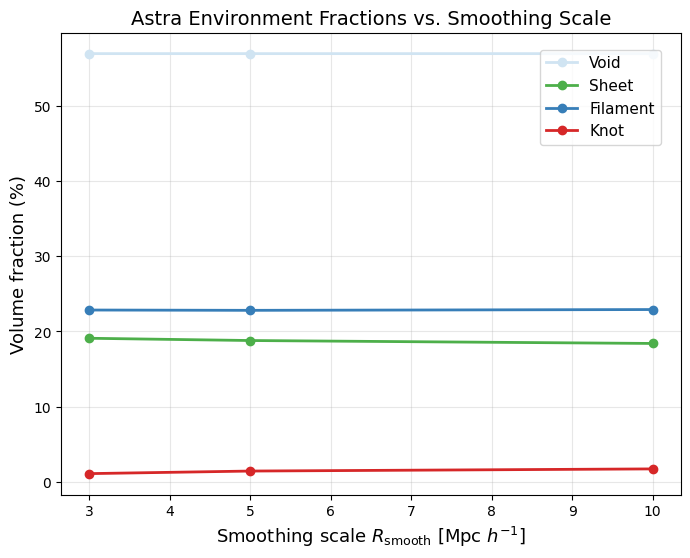

💾 Figure saved → /home/qarni/galaxy_evolution_project/data_desi_dr1/../figures/astra_scale_dependence.png


In [27]:
# ==============================================================
#  Cell 12 — Plot Astra scale dependence results (updated colors)
# ==============================================================

import pandas as pd
import matplotlib.pyplot as plt
import os

DATA_DIR = os.path.expanduser("~/galaxy_evolution_project/data_desi_dr1")
FIG_DIR  = os.path.join(DATA_DIR, "../figures")
os.makedirs(FIG_DIR, exist_ok=True)

# --------------------------------------------------------------
# 1. Load summary table
# --------------------------------------------------------------
csv_file = os.path.join(DATA_DIR, "astra_scale_dependence_summary.csv")
df = pd.read_csv(csv_file)

# --------------------------------------------------------------
# 2. Compute averages over d_border
# --------------------------------------------------------------
df_mean = df.groupby("R_smooth").mean(numeric_only=True).reset_index()

# --------------------------------------------------------------
# 3. Plot with updated cosmic-web colors
# --------------------------------------------------------------

# SAME COLORS as all previous plots:
colors = {
    "Void":     "#d0e4f2",
    "Sheet":    "#4daf4a",
    "Filament": "#377eb8",
    "Knot":     "#d62728",
}

plt.figure(figsize=(8,6))

plt.plot(df_mean["R_smooth"], df_mean["Void"]*100,
         "o-", lw=2, color=colors["Void"], label="Void")

plt.plot(df_mean["R_smooth"], df_mean["Sheet"]*100,
         "o-", lw=2, color=colors["Sheet"], label="Sheet")

plt.plot(df_mean["R_smooth"], df_mean["Filament"]*100,
         "o-", lw=2, color=colors["Filament"], label="Filament")

plt.plot(df_mean["R_smooth"], df_mean["Knot"]*100,
         "o-", lw=2, color=colors["Knot"], label="Knot")

plt.xlabel(r"Smoothing scale $R_{\rm smooth}$ [Mpc $h^{-1}$]", fontsize=13)
plt.ylabel("Volume fraction (%)", fontsize=13)
plt.title("Astra Environment Fractions vs. Smoothing Scale", fontsize=14)
plt.grid(alpha=0.3)

# --------------------------------------------------------------
# 4. Move legend slightly left to avoid line touching
# --------------------------------------------------------------
plt.legend(frameon=True, fontsize=11, loc="upper right", bbox_to_anchor=(0.98, 0.98))

# --------------------------------------------------------------
# 5. Save figure
# --------------------------------------------------------------
fig_path = os.path.join(FIG_DIR, "astra_scale_dependence.png")
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"💾 Figure saved → {fig_path}")


Loaded 2,383,673 DESI DR1 galaxies
Loaded T-Web: (128, 128, 128)
Assigning T-Web env...
Environment labels assigned.
Using 2,363,478 galaxies with z < 1.2

Evolution Table:
    z_mid  N_galaxies  Void  Sheet  Filament   Knot  Void_err  Sheet_err  \
0    0.05        6768   0.0  13.61     80.05   6.34       0.1       0.42   
1    0.15        6315   0.0  41.69     56.22   2.09       0.1       0.62   
2    0.25       29278   0.0  33.78     56.31   9.92       0.1       0.28   
3    0.35      131397   0.0  15.47     59.64  24.89       0.1       0.10   
4    0.45      216845   0.0  13.70     59.35  26.96       0.1       0.07   
5    0.55      291306   0.0  13.24     60.86  25.89       0.1       0.06   
6    0.65      355194   0.0  12.55     61.42  26.03       0.1       0.06   
7    0.75      418863   0.0  11.88     61.19  26.93       0.1       0.05   
8    0.85      443046   0.0  12.31     61.43  26.26       0.0       0.05   
9    0.95      291871   0.0  20.34     58.49  21.17       0.0      

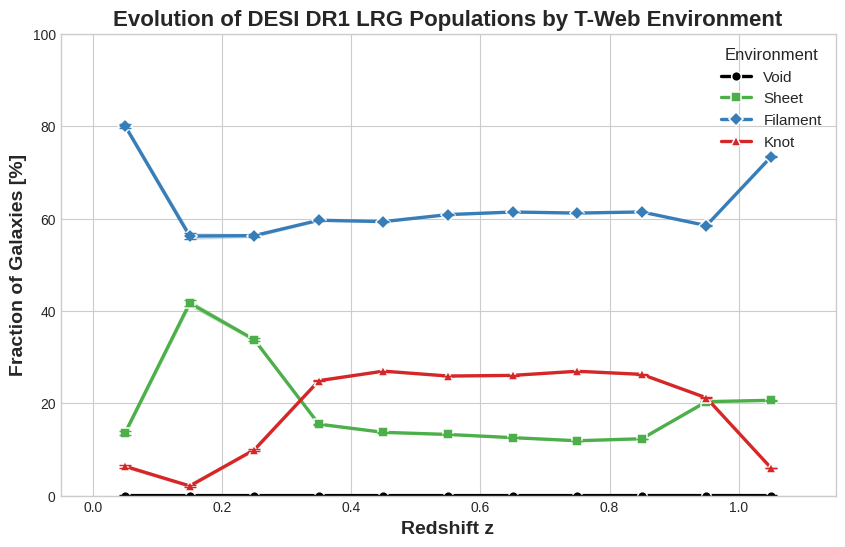

Saved → /home/qarni/galaxy_evolution_project/data_desi_dr1/../figures/tweb_environment_evolution_redshift_FIXED.png


In [33]:
# =====================================================
#  T-Web Redshift Evolution with Error Bars (Fixed Version)
# =====================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import h5py

# -----------------------------------------------------
# Paths
# -----------------------------------------------------
DATA_DIR = os.path.expanduser("~/galaxy_evolution_project/data_desi_dr1")
CATALOG_FILE = os.path.join(DATA_DIR, "desi_cleaned_dr1.csv")
FIG_DIR = os.path.join(DATA_DIR, "../figures")
os.makedirs(FIG_DIR, exist_ok=True)

# -----------------------------------------------------
# Load Galaxy Catalog
# -----------------------------------------------------
df = pd.read_csv(CATALOG_FILE)
print(f"Loaded {len(df):,} DESI DR1 galaxies")

# -----------------------------------------------------
# Load T-Web map
# -----------------------------------------------------
tweb_file = os.path.join(DATA_DIR, "tweb_environment_map.h5")
with h5py.File(tweb_file, "r") as f:
    env_map = f["env_map"][:]

N = env_map.shape[0]
box_size = 640.0
dx = box_size / N

print("Loaded T-Web:", env_map.shape)

# -----------------------------------------------------
# Assign T-Web environment
# -----------------------------------------------------
print("Assigning T-Web env...")

def rescale(arr):
    return (arr - arr.min()) / (arr.max() - arr.min()) * box_size

df["x_scaled"] = rescale(df["X_Mpc"])
df["y_scaled"] = rescale(df["Y_Mpc"])
df["z_scaled"] = rescale(df["Z_Mpc"])

ix = np.clip((df["x_scaled"] / dx).astype(int), 0, N - 1)
iy = np.clip((df["y_scaled"] / dx).astype(int), 0, N - 1)
iz = np.clip((df["z_scaled"] / dx).astype(int), 0, N - 1)

df["env_label"] = env_map[ix, iy, iz]

print("Environment labels assigned.")

# -----------------------------------------------------
# Select z < 1.2
# -----------------------------------------------------
df = df[df["Z_not4clus"] < 1.2].copy()
print(f"Using {len(df):,} galaxies with z < 1.2")

z_bins = np.linspace(0, 1.1, 12)
df["z_bin"] = pd.cut(df["Z_not4clus"], bins=z_bins)

# -----------------------------------------------------
# Compute fractions with Wilson errors
# -----------------------------------------------------
labels = ["Void", "Sheet", "Filament", "Knot"]
env_ids = [0, 1, 2, 3]

results = []

for z_bin, group in df.groupby("z_bin", observed=False):
    total = len(group)
    if total < 20:
        continue

    counts = group["env_label"].value_counts().reindex(env_ids).fillna(0)
    fractions = counts / total * 100  # percent

    errors = []

    # --- FIXED ERROR CALCULATION ---
    for i, count in enumerate(counts):
        p = count / total
        if p > 0:
            z = 1.0
            denom = 1 + z**2 / total
            center = (p + z**2/(2*total)) / denom
            margin = z*np.sqrt(p*(1-p)/total + z**2/(4*total**2)) / denom

            ci_low = (center - margin) * 100
            ci_high = (center + margin) * 100

            frac_i = fractions.iloc[i]
            error = max(frac_i - ci_low, ci_high - frac_i)
        else:
            error = 0.1

        errors.append(error)

    results.append([z_bin.mid, total] + list(fractions) + errors)

cols = ["z_mid", "N_galaxies"] + labels + [lab + "_err" for lab in labels]
df_evol = pd.DataFrame(results, columns=cols)

print("\nEvolution Table:")
print(df_evol.round(2))

# -----------------------------------------------------
# Plot
# -----------------------------------------------------
colors = ["black", "#4daf4a", "#377eb8", "#d62728"]
markers = ["o", "s", "D", "^"]

plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))

for i, lab in enumerate(labels):
    z_vals = df_evol["z_mid"]
    frac_vals = df_evol[lab]
    err_vals = df_evol[f"{lab}_err"]

    ax.plot(z_vals, frac_vals, marker=markers[i], markersize=7,
            color=colors[i], linewidth=2.4, label=lab,
            markeredgecolor="white", markeredgewidth=1.1)

    ax.errorbar(z_vals, frac_vals, yerr=err_vals, fmt="none",
                ecolor=colors[i], elinewidth=1.4, capsize=4)

    ax.fill_between(z_vals, frac_vals - err_vals, frac_vals + err_vals,
                    color=colors[i], alpha=0.18)

ax.set_xlabel("Redshift z", fontsize=14, fontweight="bold")
ax.set_ylabel("Fraction of Galaxies [%]", fontsize=14, fontweight="bold")
ax.set_title("Evolution of DESI DR1 LRG Populations by T-Web Environment",
             fontsize=16, fontweight="bold")

ax.legend(title="Environment", fontsize=11, title_fontsize=12)
ax.set_xlim(-0.05, 1.15)
ax.set_ylim(0, df_evol[labels].max().max() * 1.25)

# Save
outfig = os.path.join(FIG_DIR, "tweb_environment_evolution_redshift_FIXED.png")
plt.savefig(outfig, dpi=450, bbox_inches='tight', facecolor='white')
plt.show()

print(f"Saved → {outfig}")


Loaded 2,383,673 DESI DR1 galaxies
Loaded astra_labels.npy: (128, 128, 128)
💾 Saved astra_labels.npy → /home/qarni/galaxy_evolution_project/data_desi_dr1/astra_labels.npy
Assigning ASTRA env...
ASTRA environment labels assigned.
Using 2,363,478 galaxies with z < 1.2

ASTRA Evolution Table:
    z_mid  N_galaxies  Void  Sheet  Filament   Knot  Void_err  Sheet_err  \
0    0.05        6768   0.0   3.71     96.29   0.00       0.1       0.24   
1    0.15        6315   0.0  29.82     70.18   0.00       0.1       0.58   
2    0.25       29278   0.0  25.23     74.07   0.70       0.1       0.25   
3    0.35      131397   0.0   2.60     56.56  40.84       0.1       0.04   
4    0.45      216845   0.0   1.23     37.82  60.95       0.1       0.02   
5    0.55      291306   0.0   0.96     34.41  64.63       0.1       0.02   
6    0.65      355194   0.0   1.14     32.76  66.11       0.1       0.02   
7    0.75      418863   0.0   1.01     34.78  64.21       0.1       0.02   
8    0.85      443046   0

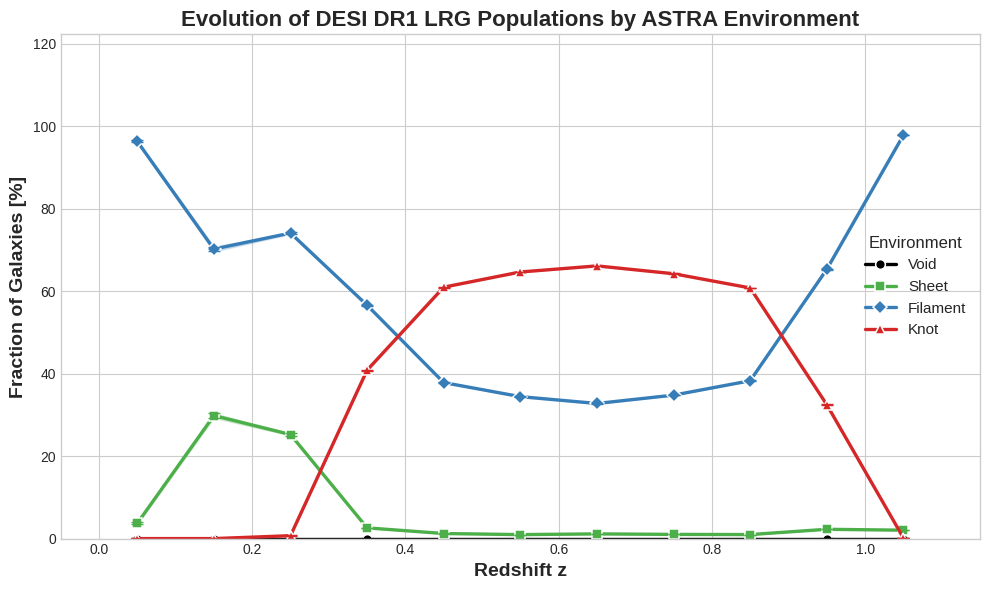


Saved → /home/qarni/galaxy_evolution_project/data_desi_dr1/../figures/astra_environment_evolution_redshift.png


In [41]:
# ==========================================================
#  ASTRA Redshift Evolution with Wilson Error Bars
#  USING astra_environment_map.h5 AND saving astra_labels.npy
# ==========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import h5py

# -----------------------------------------------------
# Paths
# -----------------------------------------------------
DATA_DIR = os.path.expanduser("~/galaxy_evolution_project/data_desi_dr1")
CATALOG_FILE = os.path.join(DATA_DIR, "desi_cleaned_dr1.csv")
ASTRA_H5 = os.path.join(DATA_DIR, "astra_environment_map.h5")
ASTRA_NPY = os.path.join(DATA_DIR, "astra_labels.npy")

FIG_DIR = os.path.join(DATA_DIR, "../figures")
os.makedirs(FIG_DIR, exist_ok=True)

# -----------------------------------------------------
# Load Galaxy Catalog
# -----------------------------------------------------
df = pd.read_csv(CATALOG_FILE)
print(f"Loaded {len(df):,} DESI DR1 galaxies")

# -----------------------------------------------------
# Load ASTRA environment map FROM HDF5
# -----------------------------------------------------
with h5py.File(ASTRA_H5, "r") as f:
    env_map = f["env_map"][:]      # shape = (128,128,128)

print("Loaded astra_labels.npy:", env_map.shape)

# -----------------------------------------------------
# ALSO SAVE astra_labels.npy for consistency
# -----------------------------------------------------
np.save(ASTRA_NPY, env_map)
print(f"💾 Saved astra_labels.npy → {ASTRA_NPY}")

# -----------------------------------------------------
# Assign ASTRA environment to galaxies
# -----------------------------------------------------
N = env_map.shape[0]
box_size = 640.0
dx = box_size / N

print("Assigning ASTRA env...")

def rescale(arr):
    return (arr - arr.min()) / (arr.max() - arr.min()) * box_size

df["x_scaled"] = rescale(df["X_Mpc"])
df["y_scaled"] = rescale(df["Y_Mpc"])
df["z_scaled"] = rescale(df["Z_Mpc"])

ix = np.clip((df["x_scaled"] / dx).astype(int), 0, N - 1)
iy = np.clip((df["y_scaled"] / dx).astype(int), 0, N - 1)
iz = np.clip((df["z_scaled"] / dx).astype(int), 0, N - 1)

df["env_label"] = env_map[ix, iy, iz]

print("ASTRA environment labels assigned.")

# -----------------------------------------------------
# Restrict to z < 1.2
# -----------------------------------------------------
df = df[df["Z_not4clus"] < 1.2].copy()
print(f"Using {len(df):,} galaxies with z < 1.2")

z_bins = np.linspace(0, 1.1, 12)
df["z_bin"] = pd.cut(df["Z_not4clus"], bins=z_bins)

# -----------------------------------------------------
# Compute ASTRA fractions per redshift bin
# -----------------------------------------------------
labels = ["Void", "Sheet", "Filament", "Knot"]
env_ids = [0, 1, 2, 3]

results = []

for z_bin, group in df.groupby("z_bin", observed=False):
    total = len(group)
    if total < 20:
        continue

    counts = group["env_label"].value_counts().reindex(env_ids).fillna(0)
    fractions = counts / total * 100

    errors = []

    for i, count in enumerate(counts):
        p = count / total

        if p > 0:
            z = 1.0
            denom = 1 + z**2 / total
            center = (p + z**2/(2*total)) / denom
            margin = z*np.sqrt(p*(1-p)/total + z**2/(4*total**2)) / denom

            ci_low = (center - margin) * 100
            ci_high = (center + margin) * 100

            frac_i = fractions.iloc[i]
            error = max(frac_i - ci_low, ci_high - frac_i)
        else:
            error = 0.1

        errors.append(error)

    results.append([z_bin.mid, total] + list(fractions) + errors)

cols = ["z_mid", "N_galaxies"] + labels + [lab + "_err" for lab in labels]
df_evol = pd.DataFrame(results, columns=cols)

print("\nASTRA Evolution Table:")
print(df_evol.round(2))

# -----------------------------------------------------
# Plot Colors (Void = BLACK)
# -----------------------------------------------------
colors = ["black", "#4daf4a", "#377eb8", "#d62728"]
markers = ["o", "s", "D", "^"]

plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))

for i, lab in enumerate(labels):
    z_vals = df_evol["z_mid"]
    y_vals = df_evol[lab]
    err_vals = df_evol[f"{lab}_err"]

    ax.plot(z_vals, y_vals,
            marker=markers[i], markersize=7,
            color=colors[i], linewidth=2.4,
            label=lab,
            markeredgecolor="white", markeredgewidth=1.1)

    ax.errorbar(z_vals, y_vals, yerr=err_vals,
                fmt="none", ecolor=colors[i],
                elinewidth=1.4, capsize=4)

    ax.fill_between(z_vals, y_vals - err_vals, y_vals + err_vals,
                    color=colors[i], alpha=0.18)

# -----------------------------------------------------
# Styling
# -----------------------------------------------------
ax.set_xlabel("Redshift z", fontsize=14, fontweight="bold")
ax.set_ylabel("Fraction of Galaxies [%]", fontsize=14, fontweight="bold")
ax.set_title("Evolution of DESI DR1 LRG Populations by ASTRA Environment",
             fontsize=16, fontweight="bold")

ax.legend(title="Environment", fontsize=11, title_fontsize=12)
ax.set_xlim(-0.05, 1.15)
ax.set_ylim(0, df_evol[labels].max().max() * 1.25)

plt.tight_layout()

# -----------------------------------------------------
# Save Figure
# -----------------------------------------------------
outfig = os.path.join(FIG_DIR, "astra_environment_evolution_redshift.png")
plt.savefig(outfig, dpi=450, bbox_inches='tight', facecolor='white')
plt.show()

print(f"\nSaved → {outfig}")
